In [1]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd
import matplotlib

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

# split the data into train and test
from sklearn.model_selection import train_test_split

# to build linear regression_model
import statsmodels.api as sm

# to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
!pip install folium
sns.set()
sns.set_palette(palette='deep')
import folium
from folium.plugins import FastMarkerCluster

In [3]:
dfa=pd.read_excel('innercity.xlsx')
df=dfa.copy()

In [4]:
df.head()

,cid,dayhours,price,room_bed,room_bath,living_measure,lot_measure,ceil,coast,sight,...,basement,yr_built,yr_renovated,zipcode,lat,long,living_measure15,lot_measure15,furnished,total_area
0,3876100940,20150427T000000,600000,4.0,1.75,3050.0,9440.0,1,0,0.0,...,1250.0,1966,0,98034,47.7228,-122.183,2020.0,8660.0,0.0,12490
1,3145600250,20150317T000000,190000,2.0,1.00,670.0,3101.0,1,0,0.0,...,0.0,1948,0,98118,47.5546,-122.274,1660.0,4100.0,0.0,3771
2,7129303070,20140820T000000,735000,4.0,2.75,3040.0,2415.0,2,1,4.0,...,0.0,1966,0,98118,47.5188,-122.256,2620.0,2433.0,0.0,5455
3,7338220280,20141010T000000,257000,3.0,2.50,1740.0,3721.0,2,0,0.0,...,0.0,2009,0,98002,47.3363,-122.213,2030.0,3794.0,0.0,5461
4,7950300670,20150218T000000,450000,2.0,1.00,1120.0,4590.0,1,0,0.0,...,0.0,1924,0,98118,47.5663,-122.285,1120.0,5100.0,0.0,5710


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cid               21613 non-null  int64  
 1   dayhours          21613 non-null  object 
 2   price             21613 non-null  int64  
 3   room_bed          21505 non-null  float64
 4   room_bath         21505 non-null  float64
 5   living_measure    21596 non-null  float64
 6   lot_measure       21571 non-null  float64
 7   ceil              21571 non-null  object 
 8   coast             21612 non-null  object 
 9   sight             21556 non-null  float64
 10  condition         21556 non-null  object 
 11  quality           21612 non-null  float64
 12  ceil_measure      21612 non-null  float64
 13  basement          21612 non-null  float64
 14  yr_built          21612 non-null  object 
 15  yr_renovated      21613 non-null  int64  
 16  zipcode           21613 non-null  int64 

In [6]:
pd.options.display.max_columns = None

In [7]:
df.head()

,cid,dayhours,price,room_bed,room_bath,living_measure,lot_measure,ceil,coast,sight,condition,quality,ceil_measure,basement,yr_built,yr_renovated,zipcode,lat,long,living_measure15,lot_measure15,furnished,total_area
0,3876100940,20150427T000000,600000,4.0,1.75,3050.0,9440.0,1,0,0.0,3,8.0,1800.0,1250.0,1966,0,98034,47.7228,-122.183,2020.0,8660.0,0.0,12490
1,3145600250,20150317T000000,190000,2.0,1.00,670.0,3101.0,1,0,0.0,4,6.0,670.0,0.0,1948,0,98118,47.5546,-122.274,1660.0,4100.0,0.0,3771
2,7129303070,20140820T000000,735000,4.0,2.75,3040.0,2415.0,2,1,4.0,3,8.0,3040.0,0.0,1966,0,98118,47.5188,-122.256,2620.0,2433.0,0.0,5455
3,7338220280,20141010T000000,257000,3.0,2.50,1740.0,3721.0,2,0,0.0,3,8.0,1740.0,0.0,2009,0,98002,47.3363,-122.213,2030.0,3794.0,0.0,5461
4,7950300670,20150218T000000,450000,2.0,1.00,1120.0,4590.0,1,0,0.0,3,7.0,1120.0,0.0,1924,0,98118,47.5663,-122.285,1120.0,5100.0,0.0,5710


In [8]:
df.shape

(21613, 23)

In [9]:
### Examine missing values
df_na = df.isna().sum()
df_na[df_na.values > 0].sort_values(ascending=False) # Find out all variables that contain missing values


living_measure15    166
room_bed            108
room_bath           108
sight                57
condition            57
lot_measure          42
ceil                 42
lot_measure15        29
furnished            29
total_area           29
living_measure       17
coast                 1
quality               1
ceil_measure          1
basement              1
yr_built              1
dtype: int64

In [10]:
df['cid'].nunique()

21436

In [11]:
df.drop(['cid'],axis='columns', inplace=True) ## drop cid column

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   dayhours          21613 non-null  object 
 1   price             21613 non-null  int64  
 2   room_bed          21505 non-null  float64
 3   room_bath         21505 non-null  float64
 4   living_measure    21596 non-null  float64
 5   lot_measure       21571 non-null  float64
 6   ceil              21571 non-null  object 
 7   coast             21612 non-null  object 
 8   sight             21556 non-null  float64
 9   condition         21556 non-null  object 
 10  quality           21612 non-null  float64
 11  ceil_measure      21612 non-null  float64
 12  basement          21612 non-null  float64
 13  yr_built          21612 non-null  object 
 14  yr_renovated      21613 non-null  int64  
 15  zipcode           21613 non-null  int64  
 16  lat               21613 non-null  float6

In [13]:
# Convert to datetime and extract year
###df['sold_year'] = pd.to_datetime(df['dayhours'], format='%Y%m%dT%H%M%S').dt.year

In [14]:
###df['sold_year'].unique()

In [15]:
##df['sold_year'].nunique()

In [16]:
##df['sold_year'].value_counts()

In [17]:
###plt.figure(figsize=(20,5))

##chart=sns.boxplot(x="sold_year", y="price", data=df, palette="viridis")
##chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right', fontsize=18)
##plt.title('Year Since price distribution')
##chart;

In [18]:
# Example: assume 'dayhours' column has values like '20150427T000000'
df['dayhours'] = pd.to_datetime(df['dayhours'], format='%Y%m%dT%H%M%S')

# Set your target date
target_date = pd.to_datetime('2025-06-01')

# Calculate the number of days between the sale date and June 1, 2025
df['days_until_2025_06_01'] = (target_date - df['dayhours']).dt.days

In [19]:
df['days_until_2025_06_01'] 

0        3688
1        3729
2        3938
3        3887
4        3756
         ... 
21608    3736
21609    4029
21610    3922
21611    3768
21612    3807
Name: days_until_2025_06_01, Length: 21613, dtype: int64

In [20]:
df.drop(['dayhours'],axis='columns', inplace=True) ## drop cid column

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  21613 non-null  int64  
 1   room_bed               21505 non-null  float64
 2   room_bath              21505 non-null  float64
 3   living_measure         21596 non-null  float64
 4   lot_measure            21571 non-null  float64
 5   ceil                   21571 non-null  object 
 6   coast                  21612 non-null  object 
 7   sight                  21556 non-null  float64
 8   condition              21556 non-null  object 
 9   quality                21612 non-null  float64
 10  ceil_measure           21612 non-null  float64
 11  basement               21612 non-null  float64
 12  yr_built               21612 non-null  object 
 13  yr_renovated           21613 non-null  int64  
 14  zipcode                21613 non-null  int64  
 15  la

In [22]:
df['days_until_2025_06_01'].unique

<bound method Series.unique of 0        3688
1        3729
2        3938
3        3887
4        3756
         ... 
21608    3736
21609    4029
21610    3922
21611    3768
21612    3807
Name: days_until_2025_06_01, Length: 21613, dtype: int64>

In [23]:
df['days_until_2025_06_01'].isna().sum()

0

In [24]:
df['days_until_2025_06_01'].value_counts()

days_until_2025_06_01
3996    142
3994    131
3993    131
3981    127
3688    126
       ... 
3670      1
3795      1
3955      1
3774      1
3928      1
Name: count, Length: 372, dtype: int64

In [25]:
df['days_until_2025_06_01'].describe()

count    21613.000000
mean      3867.806922
std        113.048011
min       3658.000000
25%       3757.000000
50%       3881.000000
75%       3967.000000
max       4048.000000
Name: days_until_2025_06_01, dtype: float64

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  21613 non-null  int64  
 1   room_bed               21505 non-null  float64
 2   room_bath              21505 non-null  float64
 3   living_measure         21596 non-null  float64
 4   lot_measure            21571 non-null  float64
 5   ceil                   21571 non-null  object 
 6   coast                  21612 non-null  object 
 7   sight                  21556 non-null  float64
 8   condition              21556 non-null  object 
 9   quality                21612 non-null  float64
 10  ceil_measure           21612 non-null  float64
 11  basement               21612 non-null  float64
 12  yr_built               21612 non-null  object 
 13  yr_renovated           21613 non-null  int64  
 14  zipcode                21613 non-null  int64  
 15  la

In [27]:
df['room_bed'].unique()

array([ 4.,  2.,  3.,  1.,  5.,  6., nan,  7., 10.,  8.,  0.,  9., 33.,
       11.])

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\2162391954.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='room_bed', data=df, palette='viridis')


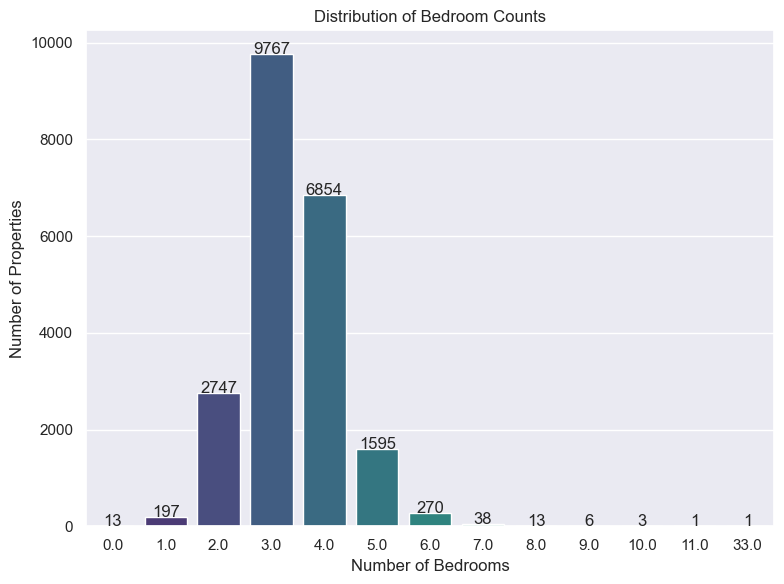

In [28]:
# Create the countplot
plt.figure(figsize=(8, 6))
ax = sns.countplot(x='room_bed', data=df, palette='viridis')

# Add count labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 0.2, int(height), ha="center")

# Add titles and axis labels
plt.title("Distribution of Bedroom Counts")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Number of Properties")

# Display the plot
plt.tight_layout()
plt.show()

In [29]:
df['room_bed'].nunique()

13

In [30]:
df["room_bed"].value_counts().sort_index()

room_bed
0.0       13
1.0      197
2.0     2747
3.0     9767
4.0     6854
5.0     1595
6.0      270
7.0       38
8.0       13
9.0        6
10.0       3
11.0       1
33.0       1
Name: count, dtype: int64

In [31]:
df['room_bed'].isna().sum()

108

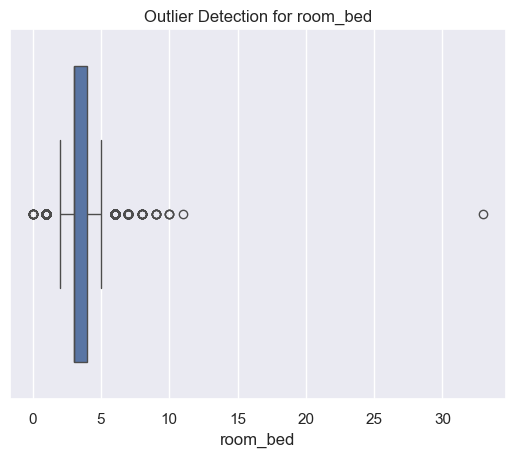

In [32]:
sns.boxplot(x=df['room_bed'])
plt.title('Outlier Detection for room_bed')
plt.show()

In [33]:
df['room_bed'].describe()

count    21505.000000
mean         3.371355
std          0.930289
min          0.000000
25%          3.000000
50%          3.000000
75%          4.000000
max         33.000000
Name: room_bed, dtype: float64

room_bed
3.0     9767
4.0     6854
2.0     2747
5.0     1595
6.0      270
1.0      197
7.0       38
8.0       13
0.0       13
9.0        6
10.0       3
33.0       1
11.0       1
Name: count, dtype: int64 



C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\44334345.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="room_bed", y="price", data=df,palette="summer");


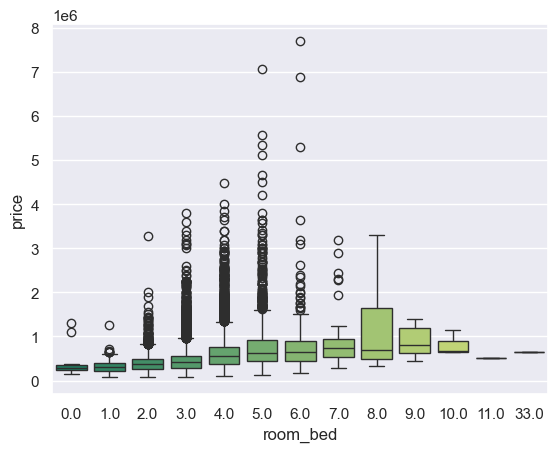

In [34]:
## Let us see the number of bedrooms of each property
print(df['room_bed'].value_counts(),'\n')


## How is the distribution of bedrooms with price.. Ideally if number of bedrooms are high, price would be high.
sns.boxplot(x="room_bed", y="price", data=df,palette="summer");

In [35]:
df['room_bath'].nunique()

30

In [36]:
df['room_bath'].unique()

array([1.75, 1.  , 2.75, 2.5 , 1.5 , 3.5 , 2.  , 2.25, 3.  , 4.  , 3.25,
       3.75,  nan, 5.  , 0.75, 5.5 , 4.25, 4.5 , 4.75, 8.  , 6.75, 5.25,
       6.  , 0.  , 1.25, 5.75, 7.5 , 6.5 , 0.5 , 7.75, 6.25])

In [37]:
df["room_bath"].value_counts().sort_index()

room_bath
0.00      10
0.50       4
0.75      72
1.00    3829
1.25       9
1.50    1439
1.75    3031
2.00    1917
2.25    2039
2.50    5358
2.75    1178
3.00     750
3.25     588
3.50     726
3.75     155
4.00     135
4.25      78
4.50     100
4.75      23
5.00      21
5.25      13
5.50      10
5.75       4
6.00       6
6.25       2
6.50       2
6.75       2
7.50       1
7.75       1
8.00       2
Name: count, dtype: int64

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\1108959943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='room_bath', data=df, palette='viridis')


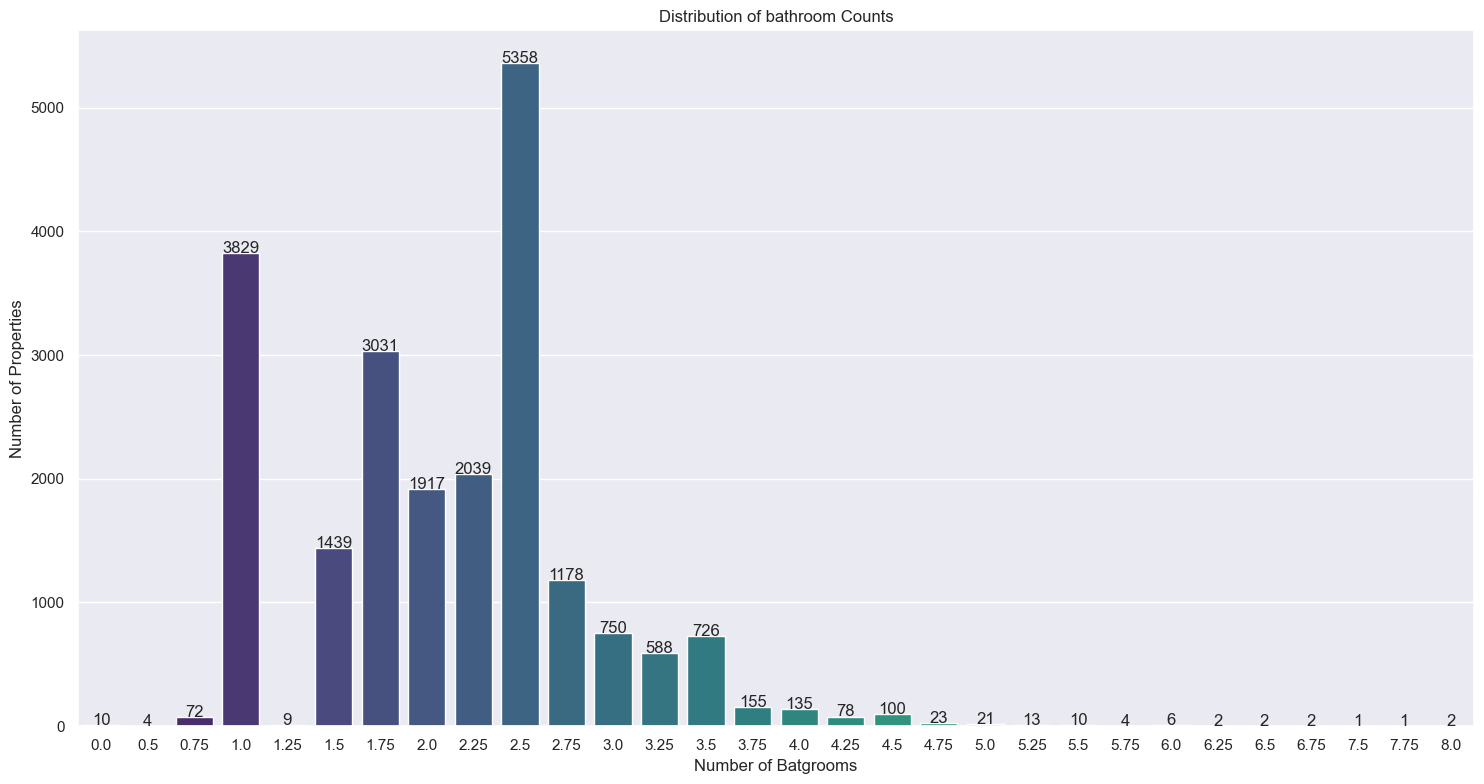

In [38]:
# Create the countplot
plt.figure(figsize=(15, 8))
ax = sns.countplot(x='room_bath', data=df, palette='viridis')

# Add count labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 0.2, int(height), ha="center")

# Add titles and axis labels
plt.title("Distribution of bathroom Counts")
plt.xlabel("Number of Batgrooms")
plt.ylabel("Number of Properties")

# Display the plot
plt.tight_layout()
plt.show()

In [39]:
df['room_bath'].isna().sum()

108

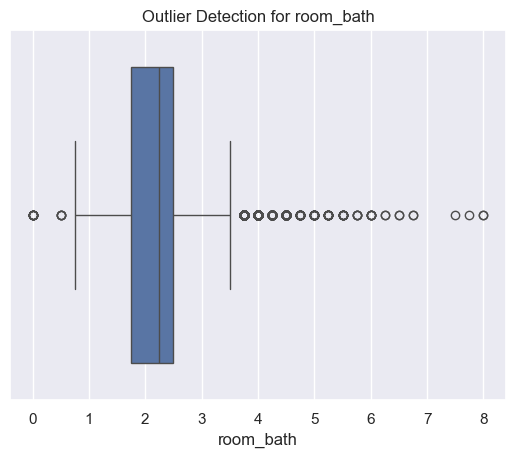

In [40]:
sns.boxplot(x=df['room_bath'])
plt.title('Outlier Detection for room_bath')
plt.show()

In [41]:
df['room_bath'].describe()

count    21505.000000
mean         2.115171
std          0.770248
min          0.000000
25%          1.750000
50%          2.250000
75%          2.500000
max          8.000000
Name: room_bath, dtype: float64

In [42]:
df['room_bath'].value_counts()

room_bath
2.50    5358
1.00    3829
1.75    3031
2.25    2039
2.00    1917
1.50    1439
2.75    1178
3.00     750
3.50     726
3.25     588
3.75     155
4.00     135
4.50     100
4.25      78
0.75      72
4.75      23
5.00      21
5.25      13
5.50      10
0.00      10
1.25       9
6.00       6
5.75       4
0.50       4
8.00       2
6.75       2
6.50       2
6.25       2
7.50       1
7.75       1
Name: count, dtype: int64

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\1333576789.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="room_bath", y="price", data=df, palette="summer")


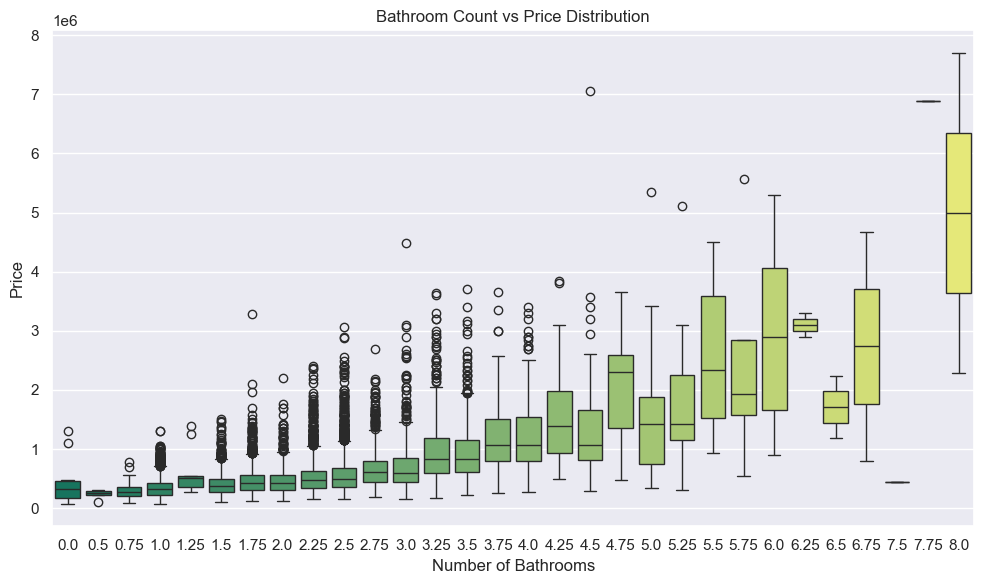

In [43]:
## How is the distribution of bedrooms with price.. Ideally if number of bedrooms are high, price would be high.
plt.figure(figsize=(10, 6))
sns.boxplot(x="room_bath", y="price", data=df, palette="summer")

plt.title("Bathroom Count vs Price Distribution")
plt.xlabel("Number of Bathrooms")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

In [44]:
null_rows = df[df['room_bed'].isnull() & df['room_bath'].isnull()]

In [45]:
print(null_rows.shape[0]) 

108


In [46]:
df['living_measure'].nunique()

1038

In [47]:
df['living_measure'].isna().sum()

17

In [48]:
df['living_measure'].unique()

array([3050.,  670., 3040., ..., 1405., 1295., 2253.])

In [49]:
df['living_measure'].value_counts()

living_measure
1300.0    138
1400.0    134
1440.0    133
1010.0    129
1800.0    129
         ... 
1728.0      1
5240.0      1
2105.0      1
3845.0      1
2253.0      1
Name: count, Length: 1038, dtype: int64

In [50]:
df['living_measure'].describe()

count    21596.000000
mean      2079.860761
std        918.496121
min        290.000000
25%       1429.250000
50%       1910.000000
75%       2550.000000
max      13540.000000
Name: living_measure, dtype: float64

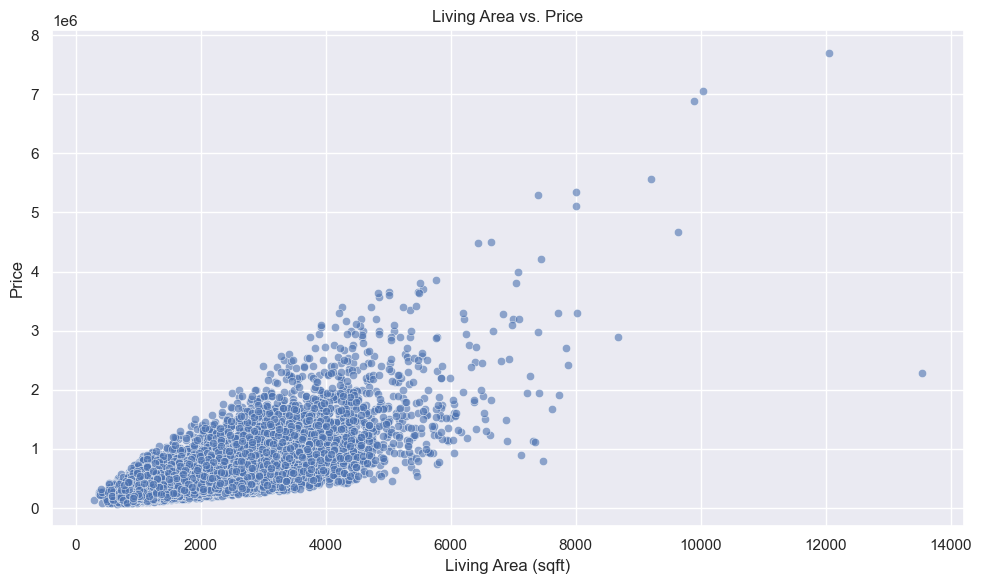

In [51]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='living_measure', y='price', data=df, alpha=0.6)

plt.title('Living Area vs. Price')
plt.xlabel('Living Area (sqft)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [52]:
null_rows = df[df['room_bed'].isnull() & df['room_bath'].isnull() & df['living_measure'].isnull()]

In [53]:
null_rows.shape[0]

17

In [54]:
null_rows[['room_bed', 'room_bath', 'living_measure']]

,room_bed,room_bath,living_measure
1451,NaN,NaN,NaN
1817,NaN,NaN,NaN
3770,NaN,NaN,NaN
4384,NaN,NaN,NaN
4962,NaN,NaN,NaN
6884,NaN,NaN,NaN
9873,NaN,NaN,NaN
10672,NaN,NaN,NaN
11058,NaN,NaN,NaN
11510,NaN,NaN,NaN


In [55]:
df = df.drop(null_rows.index)

In [56]:
null_rows

,price,room_bed,room_bath,living_measure,lot_measure,ceil,coast,sight,condition,quality,ceil_measure,basement,yr_built,yr_renovated,zipcode,lat,long,living_measure15,lot_measure15,furnished,total_area,days_until_2025_06_01
1451,465000,NaN,NaN,NaN,6360.0,1,0,0.0,3,7.0,1480.0,0.0,1954,0,98133,47.7311,-122.353,1480.0,6360.0,0.0,7840,3835
1817,865000,NaN,NaN,NaN,5527.0,2,0,0.0,3,8.0,2130.0,620.0,1901,1987,98119,47.6513,-122.368,1290.0,1764.0,0.0,8277,3678
3770,459000,NaN,NaN,NaN,6600.0,2,0,0.0,3,9.0,2790.0,0.0,2000,0,98058,47.4362,-122.109,2900.0,6752.0,1.0,9390,3888
4384,554000,NaN,NaN,NaN,12900.0,1,0,2.0,4,8.0,1720.0,1720.0,1958,0,98166,47.4426,-122.342,2100.0,10751.0,0.0,16340,3849
4962,808100,NaN,NaN,NaN,13457.0,1,0,0.0,5,9.0,3020.0,0.0,1956,0,98133,47.7174,-122.336,2120.0,7553.0,1.0,16477,3859
6884,215000,NaN,NaN,NaN,7400.0,1,0,0.0,4,7.0,1130.0,0.0,1969,0,98003,47.3437,-122.316,1540.0,7379.0,0.0,8530,3909
9873,785000,NaN,NaN,NaN,56192.0,2,0,0.0,3,9.0,3440.0,0.0,1994,0,98053,47.6969,-122.046,3150.0,44431.0,1.0,59632,3700
10672,404000,NaN,NaN,NaN,4324.0,2,0,0.0,3,8.0,2370.0,0.0,2006,0,98038,47.3515,-121.999,2370.0,4348.0,0.0,6694,3695
11058,300000,NaN,NaN,NaN,3844.0,1,0,0.0,4,6.0,820.0,0.0,1916,0,98133,47.7049,-122.349,1520.0,3844.0,0.0,4664,4021
11510,361000,NaN,NaN,NaN,7236.0,1,0,0.0,3,7.0,1200.0,0.0,1975,0,98011,47.7390,-122.194,1680.0,7800.0,0.0,8436,3772


In [57]:
### Let's examine the target column which is price

df.describe(include="all")["price"]

count     2.159600e+04
unique             NaN
top                NaN
freq               NaN
mean      5.402027e+05
std       3.674628e+05
min       7.500000e+04
25%       3.218375e+05
50%       4.500000e+05
75%       6.450000e+05
max       7.700000e+06
Name: price, dtype: float64

In [58]:
df['price'].unique()

array([600000, 190000, 735000, ..., 725126, 332100, 685530], dtype=int64)

In [59]:
df.describe()["price"]

count    2.159600e+04
mean     5.402027e+05
std      3.674628e+05
min      7.500000e+04
25%      3.218375e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64

In [60]:
df['price'].isna().sum()

0

In [61]:
df["price"].value_counts().sort_index()

price
75000      1
78000      1
80000      1
81000      1
82000      1
          ..
5350000    1
5570000    1
6890000    1
7060000    1
7700000    1
Name: count, Length: 3624, dtype: int64

In [62]:
df['price'].describe()

count    2.159600e+04
mean     5.402027e+05
std      3.674628e+05
min      7.500000e+04
25%      3.218375e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64

In [63]:
#Let's look at the distribution of price at different percentiles
print("0.5% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 0.5)))
print("  1% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 1)))
print("  5% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 5)))
print(" 10% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 10)))
print(" 50% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 50)))
print(" 90% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 90)))
print(" 95% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 95)))
print(" 99% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 99)))
print("99.5% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 99.5)))

0.5% properties have a price lower than  133390.00
  1% properties have a price lower than  153475.00
  5% properties have a price lower than  210000.00
 10% properties have a price lower than  245000.00
 50% properties have a price lower than  450000.00
 90% properties have a price lower than  887225.00
 95% properties have a price lower than  1160000.00
 99% properties have a price lower than  1970000.00
99.5% properties have a price lower than  2450250.00


In [64]:
max_price = df['price'].max()
print(f"The highest price is: {max_price}")

The highest price is: 7700000


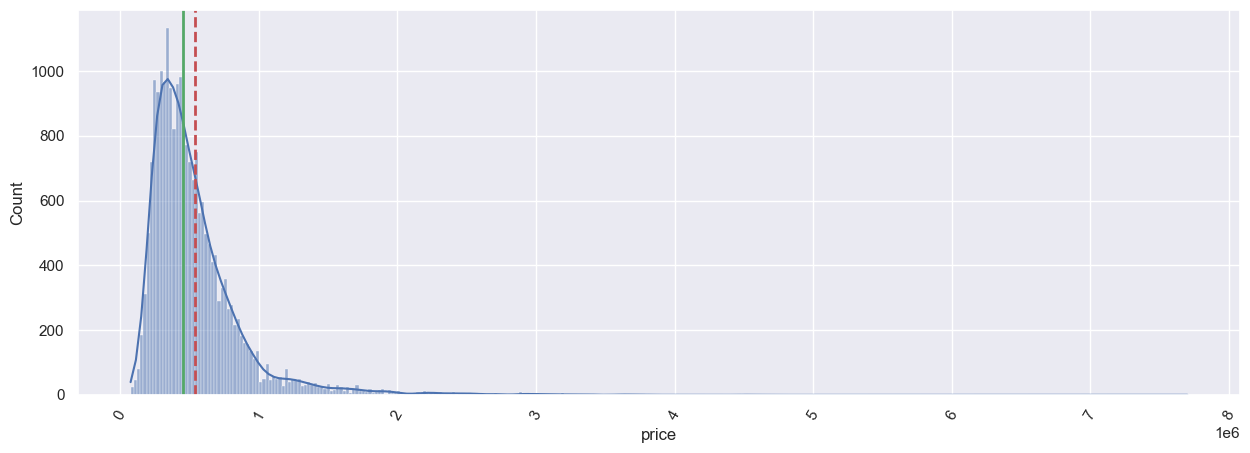

In [65]:
plt.figure(figsize=(15,5))
plt.xticks(rotation = 60)
sns.histplot(data=df,x='price',label=True,kde=True)
# Calculate statistics 
mean_value = df['price'].mean() 
median_value = df['price'].median()
plt.axvline(mean_value, color='r', linestyle='--', linewidth=2, label=f'Mean: {mean_value:.2f}')
plt.axvline(median_value, color='g', linestyle='-', linewidth=2, label=f'Median: {median_value:.2f}')



<Axes: xlabel='price'>

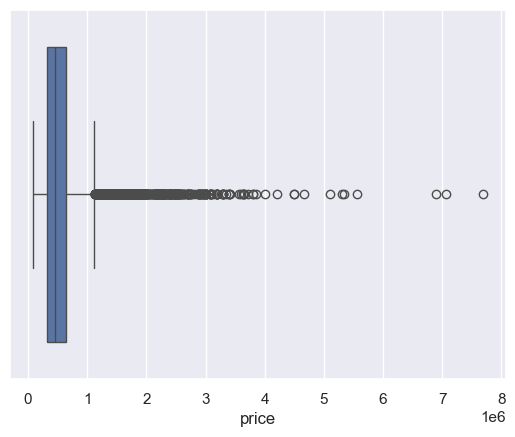

In [66]:
sns.boxplot(x=df['price'])

In [67]:
df['ceil_measure'].nunique()

946

In [68]:
df['ceil_measure'].describe()

count    21595.000000
mean      1788.339801
std        828.157467
min        290.000000
25%       1190.000000
50%       1560.000000
75%       2210.000000
max       9410.000000
Name: ceil_measure, dtype: float64

In [69]:
df['ceil_measure'].isna().sum()

1

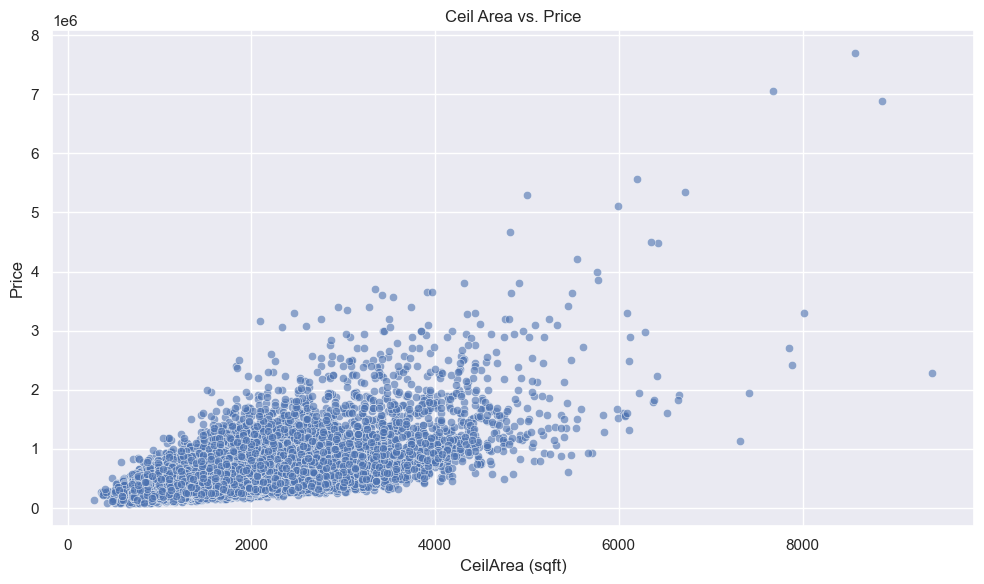

In [70]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='ceil_measure', y='price', data=df, alpha=0.6)

plt.title('Ceil Area vs. Price')
plt.xlabel('CeilArea (sqft)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [71]:
df['lot_measure'].describe()

count    2.155400e+04
mean     1.510577e+04
std      4.143688e+04
min      5.200000e+02
25%      5.040000e+03
50%      7.620000e+03
75%      1.068350e+04
max      1.651359e+06
Name: lot_measure, dtype: float64

In [72]:
df['lot_measure'].unique()

array([ 9440.,  3101.,  2415., ..., 12369.,  2332., 60467.])

In [73]:
df['lot_measure'].isna().sum()

42

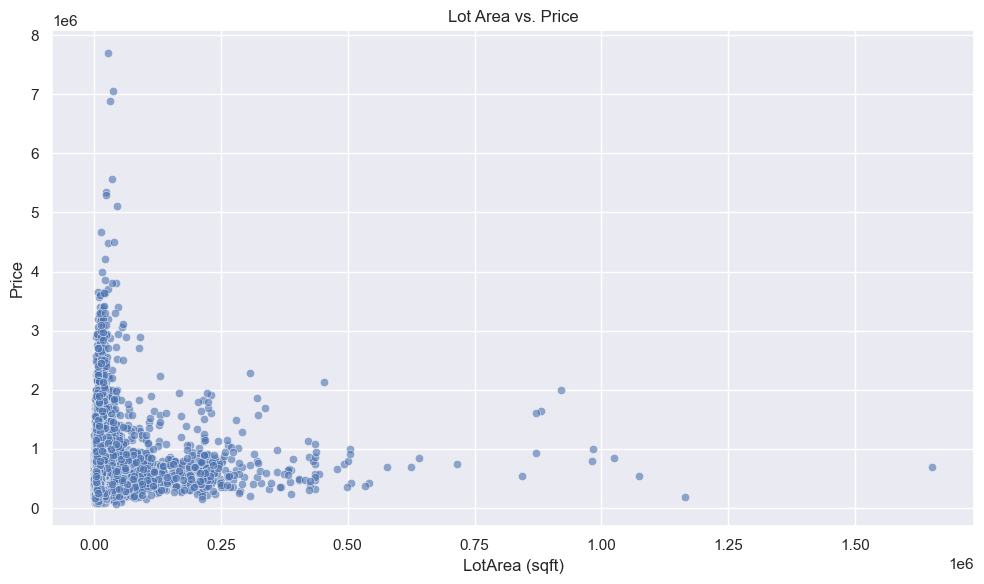

In [74]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='lot_measure', y='price', data=df, alpha=0.6)

plt.title('Lot Area vs. Price')
plt.xlabel('LotArea (sqft)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [75]:
df['ceil'].nunique()

7

In [76]:
df['ceil'].unique()

array([1, 2, 3, 1.5, 2.5, '$', nan, 3.5], dtype=object)

In [77]:
df['ceil'] = pd.to_numeric(df['ceil'], errors='coerce')

In [78]:
df['ceil'].unique()

array([1. , 2. , 3. , 1.5, 2.5, nan, 3.5])

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\3243625305.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='ceil', data=df, palette='viridis')


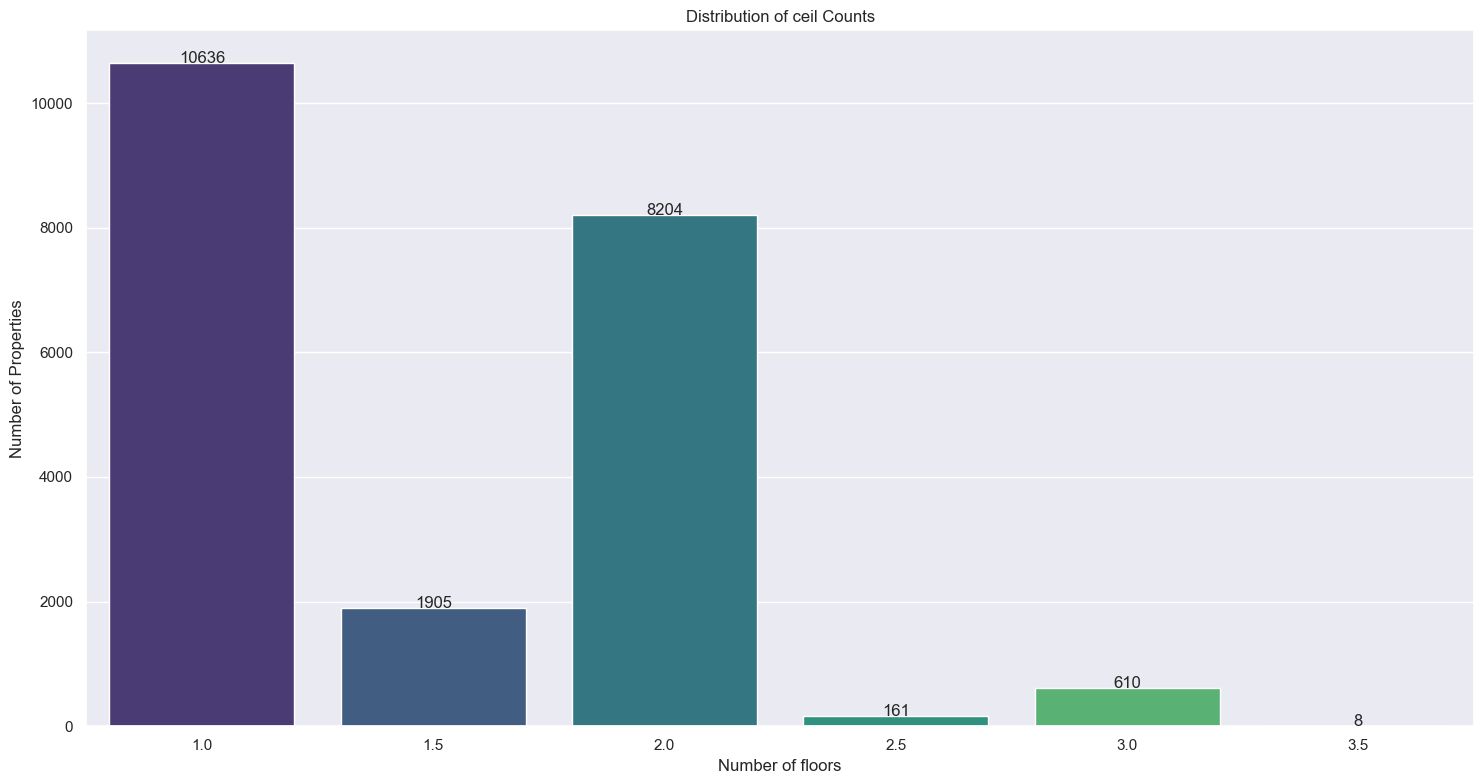

In [79]:
# Create the countplot
plt.figure(figsize=(15, 8))
ax = sns.countplot(x='ceil', data=df, palette='viridis')

# Add count labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 0.2, int(height), ha="center")

# Add titles and axis labels
plt.title("Distribution of ceil Counts")
plt.xlabel("Number of floors")
plt.ylabel("Number of Properties")

# Display the plot
plt.tight_layout()
plt.show()

In [80]:
df["ceil"].value_counts()

ceil
1.0    10636
2.0     8204
1.5     1905
3.0      610
2.5      161
3.5        8
Name: count, dtype: int64

In [81]:
df['ceil'].isna().sum()

72

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\481583096.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="ceil", y="price", data=df, palette="summer")


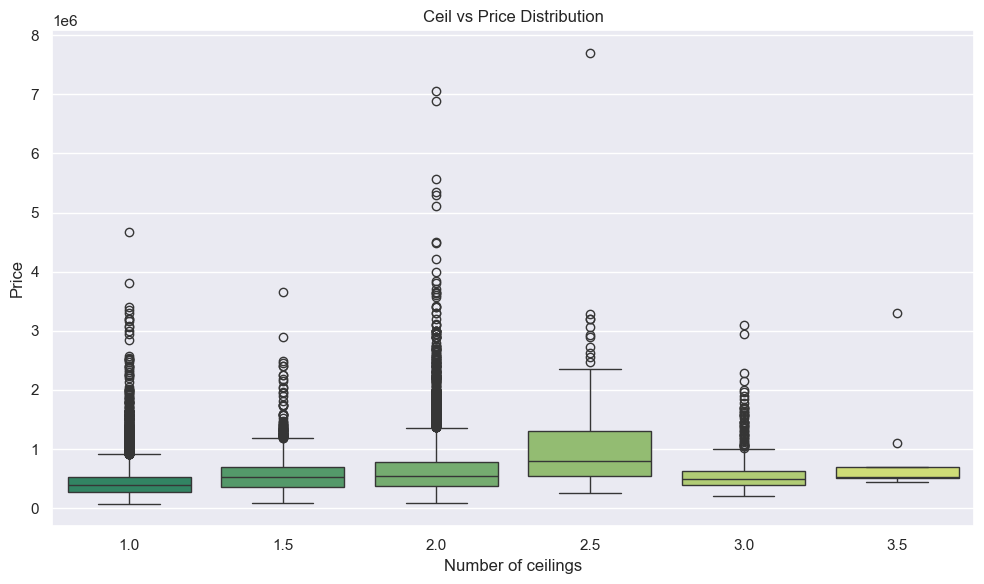

In [82]:
## How is the distribution of bedrooms with price.. Ideally if number of bedrooms are high, price would be high.
plt.figure(figsize=(10, 6))
sns.boxplot(x="ceil", y="price", data=df, palette="summer")

plt.title("Ceil vs Price Distribution")
plt.xlabel("Number of ceilings")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

In [83]:
df['coast'].nunique()

3

In [84]:
df['coast'].unique()

array([0, 1, '$', nan], dtype=object)

In [85]:
df['coast'] = pd.to_numeric(df['coast'], errors='coerce')

In [86]:
df['coast'].unique()

array([ 0.,  1., nan])

In [87]:
df['coast'].isna().sum()

31

In [88]:
df["coast"].value_counts().sort_index()

coast
0.0    21404
1.0      161
Name: count, dtype: int64

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\1781560738.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='coast', data=df, palette='viridis')


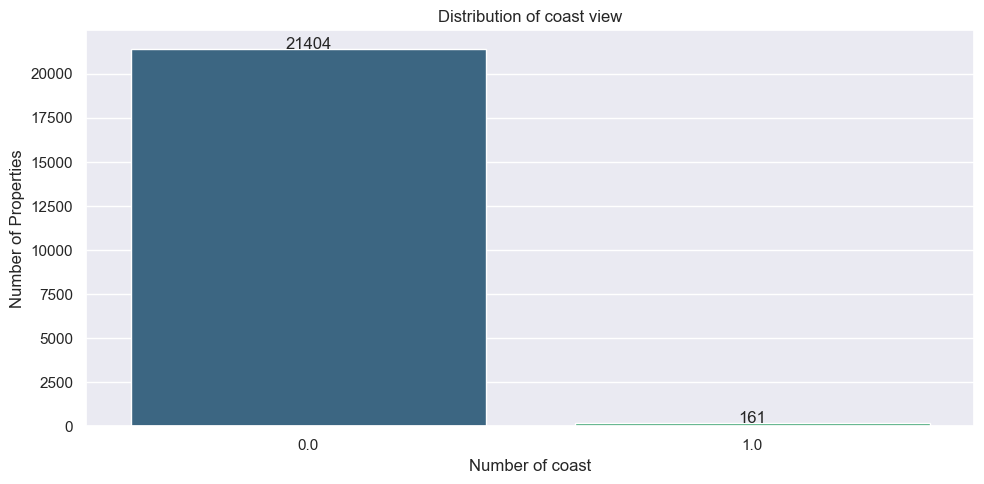

In [89]:
# Create the countplot
plt.figure(figsize=(10, 5))
ax = sns.countplot(x='coast', data=df, palette='viridis')

# Add count labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 0.2, int(height), ha="center")

# Add titles and axis labels
plt.title("Distribution of coast view")
plt.xlabel("Number of coast")
plt.ylabel("Number of Properties")

# Display the plot
plt.tight_layout()
plt.show()

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\995907858.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="coast", y="price", data=df, palette="summer")


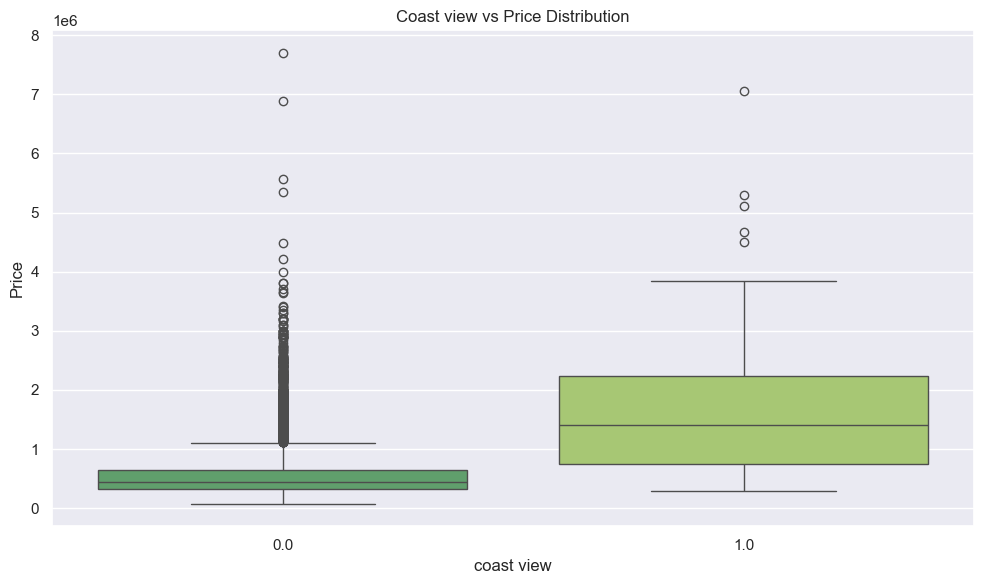

In [90]:
## How is the distribution of bedrooms with price.. Ideally if number of bedrooms are high, price would be high.
plt.figure(figsize=(10, 6))
sns.boxplot(x="coast", y="price", data=df, palette="summer")

plt.title("Coast view vs Price Distribution")
plt.xlabel("coast view")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

In [91]:
df['sight'].value_counts().sort_index()

sight
0.0    19422
1.0      332
2.0      957
3.0      510
4.0      318
Name: count, dtype: int64

In [92]:
df['sight'].isna().sum()

57

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\804209332.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='sight', data=df, palette='viridis')


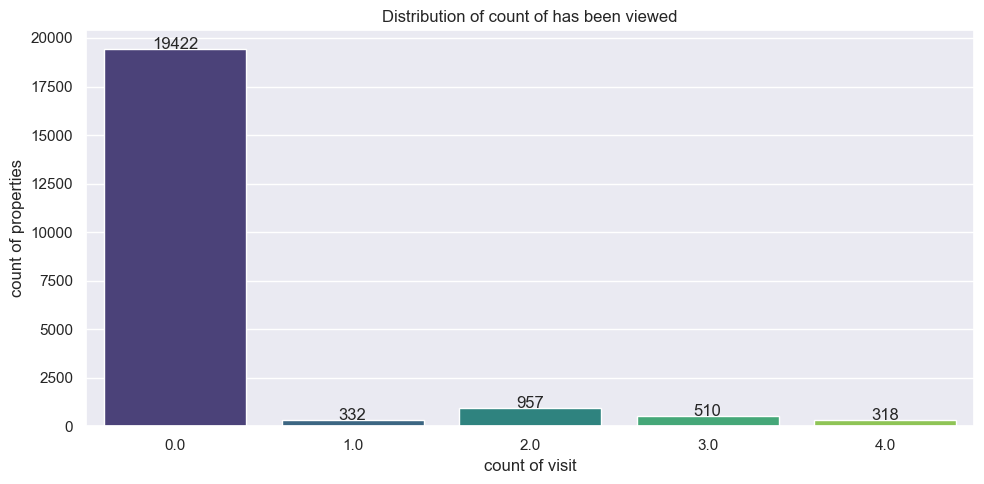

In [93]:
# Create the countplot
plt.figure(figsize=(10, 5))
ax = sns.countplot(x='sight', data=df, palette='viridis')

# Add count labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 0.2, int(height), ha="center")

# Add titles and axis labels
plt.title("Distribution of count of has been viewed")
plt.xlabel("count of visit")
plt.ylabel("count of properties")

# Display the plot
plt.tight_layout()
plt.show()

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\2495782228.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="sight", y="price", data=df, palette="summer")


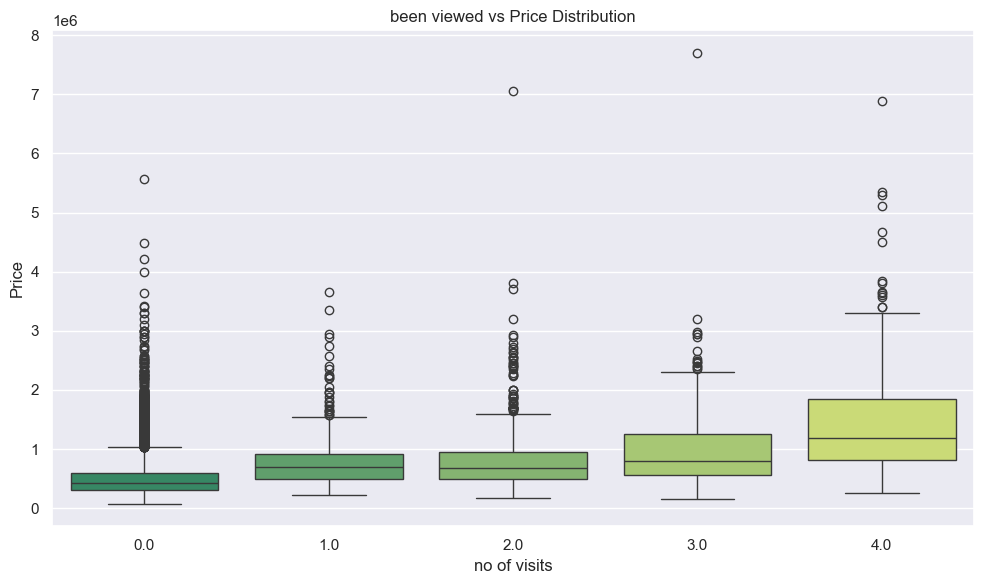

In [94]:
plt.figure(figsize=(10, 6))
sns.boxplot(x="sight", y="price", data=df, palette="summer")

plt.title("been viewed vs Price Distribution")
plt.xlabel("no of visits")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

In [95]:
df['condition'].unique()

array([3, 4, 5, 2, nan, 1, '$'], dtype=object)

In [96]:
df['condition'] = pd.to_numeric(df['condition'], errors='coerce')

In [97]:
df['condition'].value_counts().sort_index()

condition
1.0       30
2.0      171
3.0    13969
4.0     5649
5.0     1692
Name: count, dtype: int64

In [98]:
df['condition'].unique()

array([ 3.,  4.,  5.,  2., nan,  1.])

In [99]:
df['condition'].unique()

array([ 3.,  4.,  5.,  2., nan,  1.])

In [100]:
df['condition'].isna().sum()

85

In [101]:
df.groupby('condition')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
1.0,30.0,334431.666667,271172.804837,78000.0,160000.0,262500.0,431125.0,1500000.0
2.0,171.0,326423.327485,246125.471303,80000.0,189500.0,279000.0,385700.0,2560000.0
3.0,13969.0,542383.808361,365151.779311,75000.0,329800.0,450000.0,640000.0,7060000.0
4.0,5649.0,520694.707913,358402.945010,89000.0,304400.0,440000.0,625000.0,7700000.0
5.0,1692.0,612524.314421,412022.805167,110000.0,349980.0,525444.0,725000.0,3650000.0


C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\1607929296.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='condition', y='price', data=df, palette='crest')


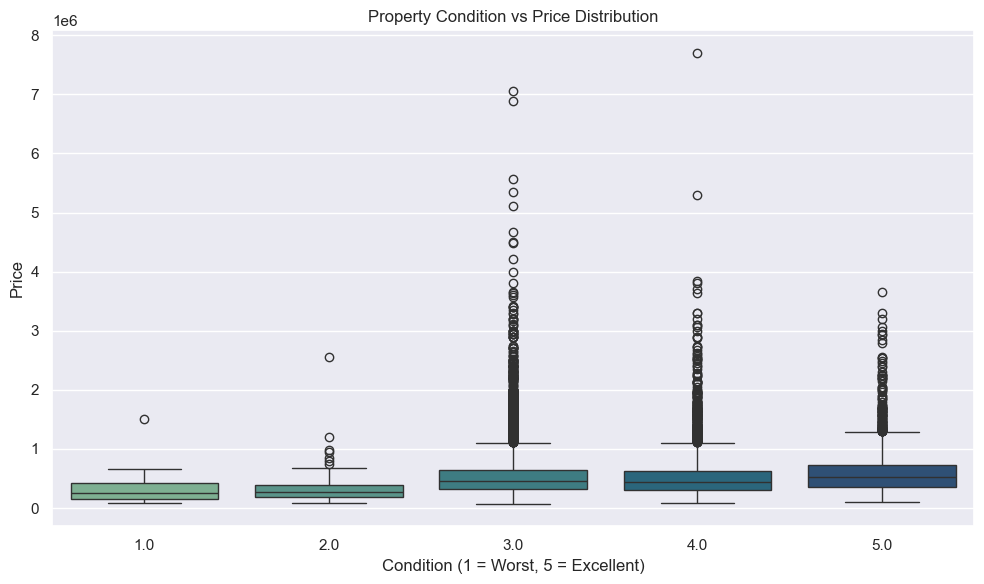

In [102]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='condition', y='price', data=df, palette='crest')

plt.title('Property Condition vs Price Distribution')
plt.xlabel('Condition (1 = Worst, 5 = Excellent)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [103]:
df['quality'].unique()

array([ 8.,  6.,  7., 10.,  9.,  5., 11., 13.,  4., 12.,  1.,  3., nan])

In [104]:
df['quality'].isna().sum()

1

In [105]:
df['quality'].value_counts().sort_index()

quality
1.0        1
3.0        3
4.0       29
5.0      242
6.0     2037
7.0     8976
8.0     6061
9.0     2610
10.0    1134
11.0     399
12.0      90
13.0      13
Name: count, dtype: int64

In [106]:
df['condition'].isna().sum()

85

In [107]:
df.groupby('quality')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
quality,,,,,,,,
1.0,1.0,1.420000e+05,NaN,142000.0,142000.00,142000.0,142000.0,142000.0
3.0,3.0,2.056667e+05,1.135180e+05,75000.0,168500.00,262000.0,271000.0,280000.0
4.0,29.0,2.143810e+05,9.430617e+04,80000.0,145000.00,205000.0,265000.0,435000.0
5.0,242.0,2.485240e+05,1.181003e+05,78000.0,175000.00,228700.0,295750.0,795000.0
6.0,2037.0,3.019175e+05,1.229824e+05,82000.0,215000.00,275053.0,367000.0,1200000.0
7.0,8976.0,4.026033e+05,1.559220e+05,90000.0,285000.00,375000.0,485000.0,2050000.0
8.0,6061.0,5.428779e+05,2.176173e+05,140000.0,390000.00,510000.0,640000.0,3070000.0
9.0,2610.0,7.740955e+05,3.166064e+05,230000.0,572028.75,720250.0,880000.0,2700000.0
10.0,1134.0,1.072347e+06,4.840508e+05,316000.0,768087.50,914327.0,1250000.0,3600000.0


C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\3240477953.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y='price', data=df, palette='crest')


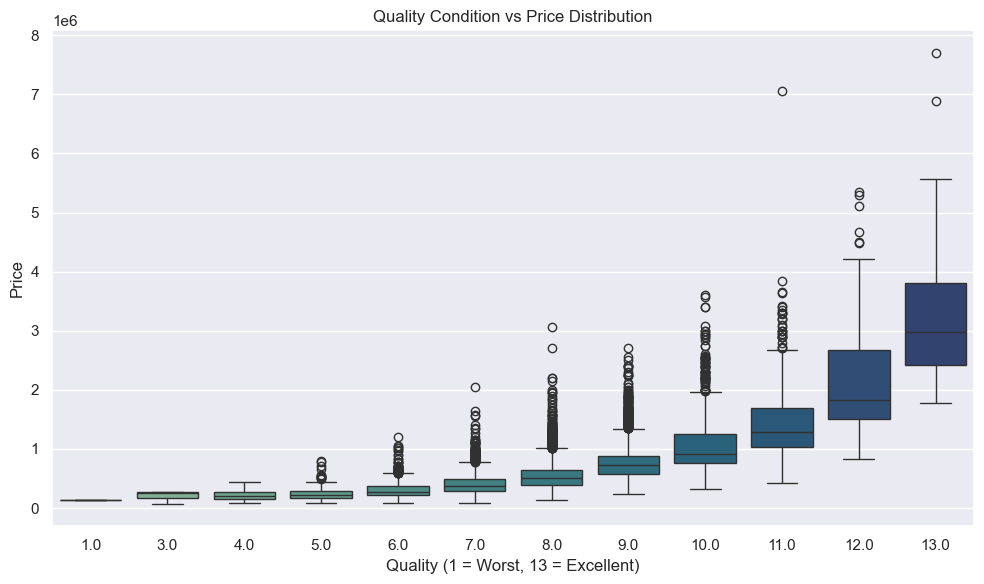

In [108]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='quality', y='price', data=df, palette='crest')

plt.title('Quality Condition vs Price Distribution')
plt.xlabel('Quality (1 = Worst, 13 = Excellent)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [109]:
df['basement'].isna().sum()

1

In [110]:
###import numpy as np
####df['basement_measure'] = df['basement_measure'].replace(0, np.nan)

In [111]:
df['basement'].value_counts()

basement
0.0       13113
600.0       221
700.0       218
500.0       214
800.0       205
          ...  
4130.0        1
2050.0        1
784.0         1
518.0         1
2180.0        1
Name: count, Length: 306, dtype: int64

In [112]:
df['basement'].describe()

count    21595.000000
mean       291.510303
std        442.514468
min          0.000000
25%          0.000000
50%          0.000000
75%        560.000000
max       4820.000000
Name: basement, dtype: float64

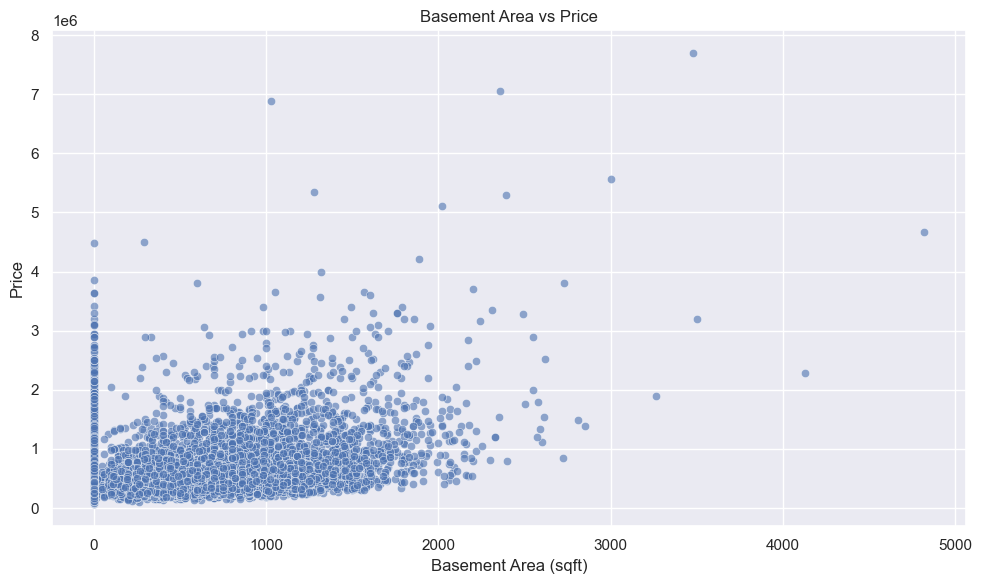

In [113]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='basement', y='price', data=df, alpha=0.6)

plt.title('Basement Area vs Price')
plt.xlabel('Basement Area (sqft)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [114]:
# Compute a safe max bin limit
max_val = df['basement'].max()
if max_val <= 5000:
    max_bin = 6000  # ensure last bin edge is higher
else:
    max_bin = max_val + 1

# Define bins again with increasing order
bins = [0, 1000, 2000, 3000, 4000, 5000, max_bin]

# Apply categorization
labels = ['Small', 'Medium', 'Large', 'X-Large', 'XX-Large', 'XXX-Large']
df['basement_size'] = pd.cut(df['basement'], bins=bins, labels=labels)

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\3669461270.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='basement_size', y='price', data=df, palette='mako')


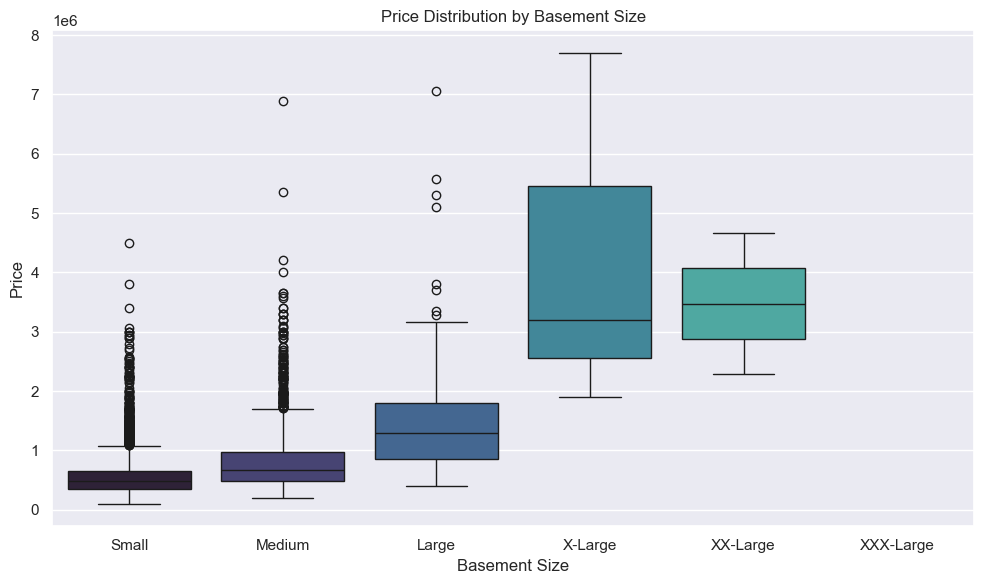

In [115]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='basement_size', y='price', data=df, palette='mako')

plt.title('Price Distribution by Basement Size')
plt.xlabel('Basement Size')
plt.ylabel('Price')
plt.tight_layout()
plt.show()  # This line is essential to display the plot

In [116]:
df['yr_built'] = pd.to_numeric(df['yr_built'], errors='coerce')

In [117]:
df['yr_built']

0        1966.0
1        1948.0
2        1966.0
3        2009.0
4        1924.0
          ...  
21608    1996.0
21609    1939.0
21610    1978.0
21611    1997.0
21612    1925.0
Name: yr_built, Length: 21596, dtype: float64

In [118]:
df['house_age_2025'] = 2025 - df['yr_built']

In [119]:
df['house_age_2025']

0         59.0
1         77.0
2         59.0
3         16.0
4        101.0
         ...  
21608     29.0
21609     86.0
21610     47.0
21611     28.0
21612    100.0
Name: house_age_2025, Length: 21596, dtype: float64

In [120]:
df['house_age_2025'].value_counts()

house_age_2025
11.0     559
19.0     453
20.0     450
21.0     433
22.0     421
        ... 
92.0      30
124.0     28
123.0     27
90.0      24
91.0      21
Name: count, Length: 116, dtype: int64

In [121]:
df['house_age_2025'].describe()

count    21581.000000
mean        53.983504
std         29.370998
min         10.000000
25%         28.000000
50%         50.000000
75%         74.000000
max        125.000000
Name: house_age_2025, dtype: float64

In [122]:
df['house_age_2025'].value_counts()

house_age_2025
11.0     559
19.0     453
20.0     450
21.0     433
22.0     421
        ... 
92.0      30
124.0     28
123.0     27
90.0      24
91.0      21
Name: count, Length: 116, dtype: int64

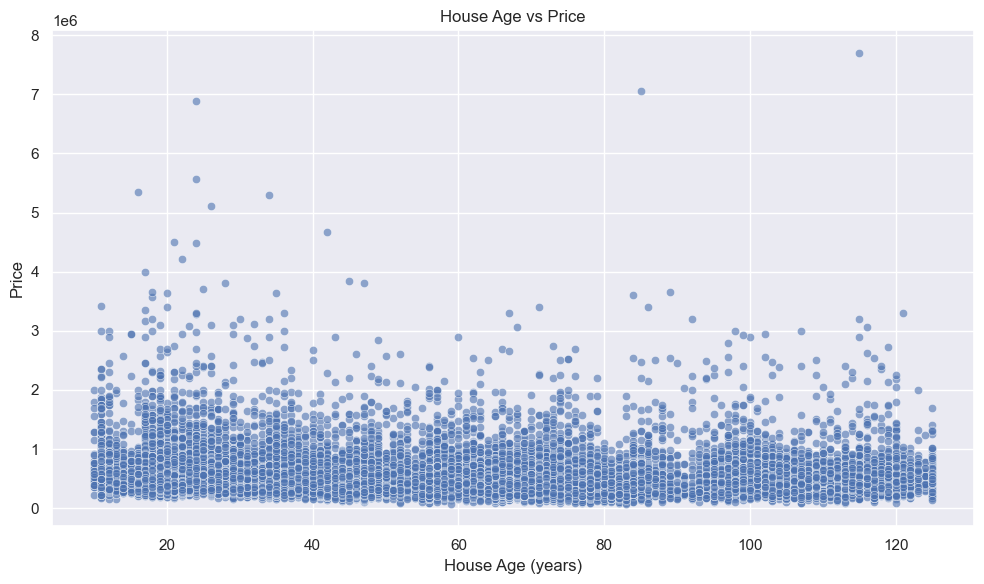

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x='house_age_2025', y='price', data=df, alpha=0.6)

plt.title('House Age vs Price')
plt.xlabel('House Age (years)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [124]:
df.drop(['yr_built'],axis='columns', inplace=True) 

In [125]:
df['yr_renovated'] 

0        0
1        0
2        0
3        0
4        0
        ..
21608    0
21609    0
21610    0
21611    0
21612    0
Name: yr_renovated, Length: 21596, dtype: int64

In [126]:
df['yr_renovated'].isna().sum()

0

In [127]:
df['yr_renovated'].value_counts()

yr_renovated
0       20683
2014       91
2013       37
2003       36
2007       35
        ...  
1944        1
1948        1
1959        1
1951        1
1954        1
Name: count, Length: 70, dtype: int64

In [128]:
df.drop(['yr_renovated'],axis='columns', inplace=True)

In [129]:
df['zipcode'].isna().sum()

0

In [130]:
df['zipcode'].nunique()

70

In [131]:
zip_avg = df.groupby('zipcode')['price'].mean().sort_values(ascending=False)

In [132]:
zip_avg

zipcode
98039    2.161300e+06
98004    1.356524e+06
98040    1.194874e+06
98112    1.096239e+06
98102    9.015162e+05
             ...     
98148    2.849086e+05
98001    2.808047e+05
98032    2.512962e+05
98168    2.403284e+05
98002    2.342840e+05
Name: price, Length: 70, dtype: float64

In [133]:
# Step 1: Identify rows where 'long' contains a '$' character
mask = df['long'].astype(str).str.contains(r'\$')

# Step 2: Convert values that are valid (non-$) to float for mode calculation
numeric_long = pd.to_numeric(df.loc[~mask, 'long'].astype(str).str.replace(',', ''), errors='coerce')

# Step 3: Compute mode (most frequent value)
long_mode = numeric_long.mode().iloc[0]

# Step 4: Replace '$' values with the mode
df.loc[mask, 'long'] = long_mode

# Step 5: Convert entire column to float (if needed)
df['long'] = pd.to_numeric(df['long'], errors='coerce')

In [134]:
df['long'].unique()

array([-122.183, -122.274, -122.256, -122.213, -122.285, -122.29 ,
       -122.333, -122.165, -122.15 , -122.178, -121.87 , -122.352,
       -122.122, -122.275, -122.234, -122.324, -122.321, -122.277,
       -122.196, -122.398, -122.019, -122.181, -122.325, -122.191,
       -122.026, -122.084, -122.3  , -122.287, -122.011, -122.127,
       -122.281, -122.221, -121.859, -121.913, -122.39 , -121.871,
       -122.013, -122.381, -122.279, -122.194, -122.201, -122.125,
       -122.379, -122.121, -122.024, -122.389, -122.305, -122.346,
       -122.375, -122.344, -122.028, -122.193, -122.209, -122.365,
       -122.28 , -122.334, -122.149, -122.388, -122.016, -122.298,
       -122.153, -121.802, -121.878, -122.218, -122.359, -122.296,
       -122.361, -122.357, -122.309, -122.056, -121.974, -122.18 ,
       -122.331, -122.374, -121.976, -121.975, -122.216, -122.188,
       -122.391, -122.31 , -122.302, -121.972, -122.22 , -122.17 ,
       -122.101, -121.888, -122.046, -122.154, -122.145, -122.

In [135]:
df['long'] = df['long'].fillna(long_mode)

In [136]:
print(df['long'].isna().sum())

0


In [137]:
## Let's study Latitude and Longitue features 

lat = df['lat'].tolist()
lon = df['long'].tolist()
locations = list(zip(lat, lon))

# 47.751076° N, -120.740135° W is the latitude and longitude of washington

map1 = folium.Map(location=[47.751076, -120.740135], zoom_start=12)
FastMarkerCluster(locations).add_to(map1)
map1

In [138]:
from math import sin, cos, sqrt, atan2, radians
def distance(lat1, lat2, lon1, lon2):
    R = 6373.0 ## Approx radius of earth in KM
    rlat1 = radians(lat1)
    rlat2 = radians(lat2)
    rlon1 = radians(lon1)
    rlon2 = radians(lon2)
    rdlon = rlon2 - rlon1
    rdlat = rlat2 - rlat1
    a = sin(rdlat / 2)**2 + cos(rlat1) * cos(rlat2) * sin(rdlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    distance = R * c
    return distance

In [139]:
# Top locations in Wasshington
toploc = {"medina": [47.6205, -122.2307], 
          "seattle": [47.6062, -122.3321], 
          "bellevue": [47.6104, -122.2007], 
          "redmond": [47.67303, -122.1215], 
          "kirkland": [47.6815, -122.2087]}
toploc = pd.DataFrame.from_dict(toploc)
toploc_trans = toploc.transpose()
toploc_trans.columns = ["lat", "long"]

# Construct distance columns
dist = []
for loc in toploc_trans.index:
    df['dist_' + loc] = df.apply(
        lambda x: distance(x.lat, toploc_trans.loc[loc, 'lat'], x.long, toploc_trans.loc[loc, 'long']),
        axis=1
    )
    dist.append('dist_' + loc)

In [140]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21596 entries, 0 to 21612
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   price                  21596 non-null  int64   
 1   room_bed               21505 non-null  float64 
 2   room_bath              21505 non-null  float64 
 3   living_measure         21596 non-null  float64 
 4   lot_measure            21554 non-null  float64 
 5   ceil                   21524 non-null  float64 
 6   coast                  21565 non-null  float64 
 7   sight                  21539 non-null  float64 
 8   condition              21511 non-null  float64 
 9   quality                21595 non-null  float64 
 10  ceil_measure           21595 non-null  float64 
 11  basement               21595 non-null  float64 
 12  zipcode                21596 non-null  int64   
 13  lat                    21596 non-null  float64 
 14  long                   21596 non-null  floa

In [141]:
## This dictionary contains only the names of the new distance related columns.

dist

['dist_medina',
 'dist_seattle',
 'dist_bellevue',
 'dist_redmond',
 'dist_kirkland']

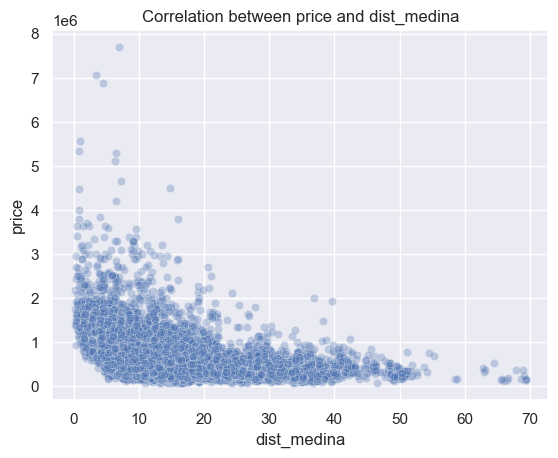

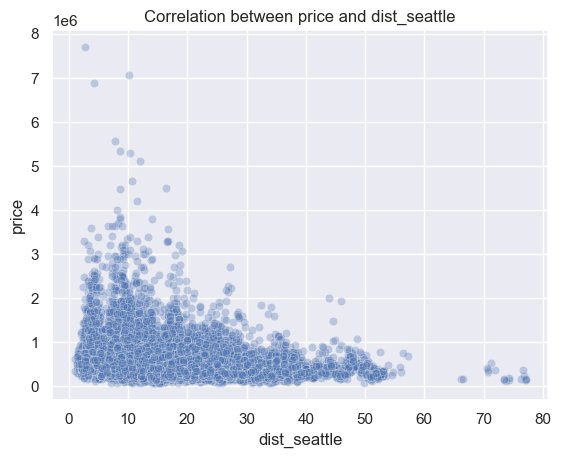

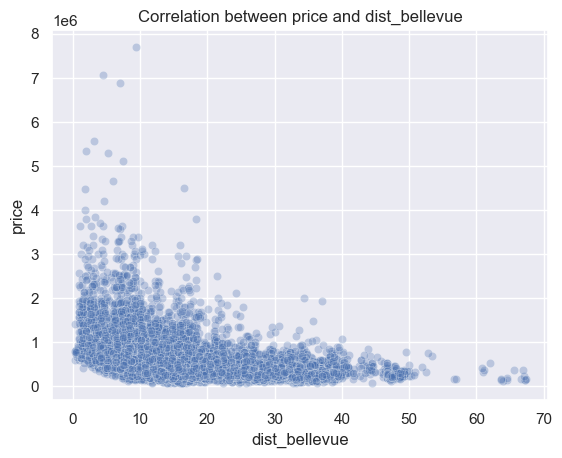

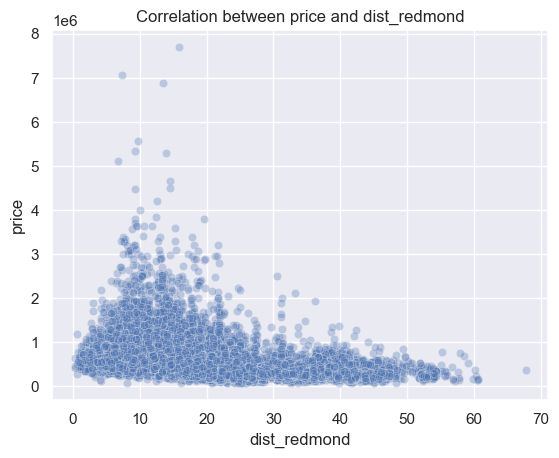

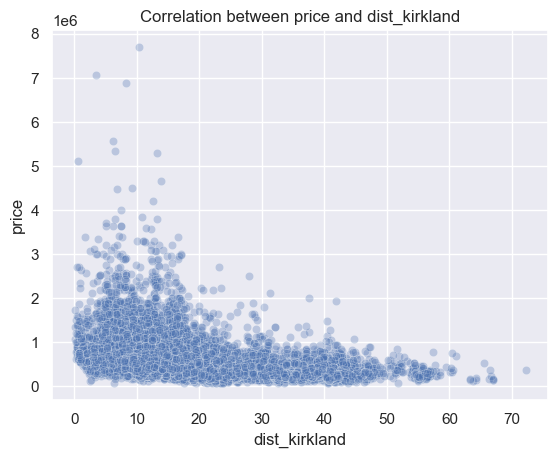

In [142]:
from scipy import stats
for distance in dist:
    sns.scatterplot(x=distance, y="price", data=df, alpha=0.3)
    plt.title("Correlation between price and "+distance)
    plt.show()

In [143]:
## As similar scatter plot was observed for all distance variables, let's take an average and create a new variable

df['dist_average'] = df[['dist_medina', 'dist_seattle', 'dist_bellevue', 'dist_redmond', 'dist_kirkland']].mean(axis=1) 


In [144]:
df[['dist_medina','dist_seattle', 'dist_bellevue', 'dist_redmond','dist_kirkland']].head()

,dist_medina,dist_seattle,dist_bellevue,dist_redmond,dist_kirkland
0,11.926511,17.115885,12.572340,7.200226,4.980354
1,8.017578,7.207268,8.292584,17.443696,14.940068
2,11.470307,11.275272,11.001583,19.901592,18.441537
3,31.639511,31.327998,30.502119,38.080203,38.397898
4,7.275662,5.672956,8.003489,17.064576,14.032447


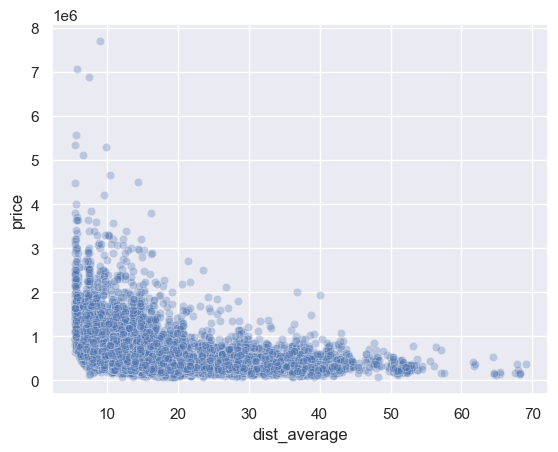

In [145]:
sns.scatterplot(x='dist_average', y="price", data=df, alpha=0.3);

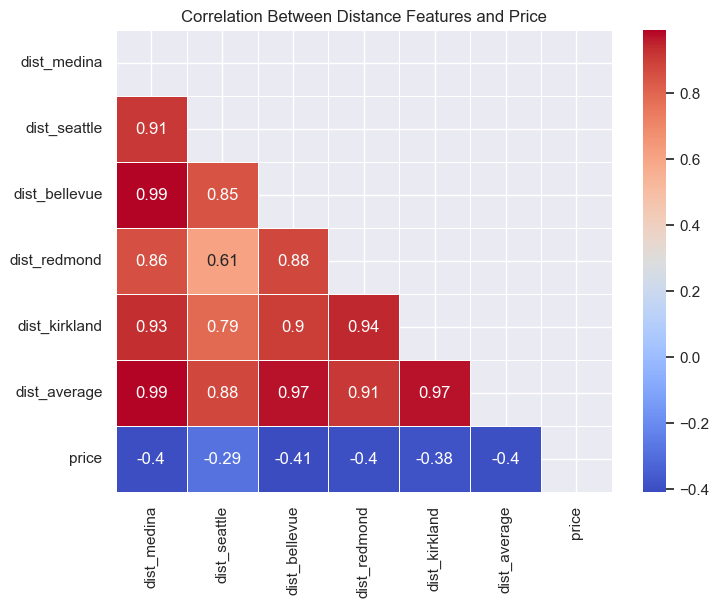

In [146]:
# Define the columns to include
cols = ['dist_medina', 'dist_seattle', 'dist_bellevue', 'dist_redmond', 'dist_kirkland', 'dist_average', 'price']

# Calculate full correlation matrix
corr_matrix = df[cols].corr()

# Create a mask for the upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, mask=mask, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Between Distance Features and Price")
plt.show()

In [147]:
df['living_measure15'].isna().sum()

166

In [148]:
df['lot_measure15'].unique()

array([ 8660.,  4100.,  2433., ..., 11491.,  2853.,  7604.])

In [149]:
df['lot_measure15'].nunique()

8680

In [150]:
df['lot_measure15'].isna().sum()

29

In [151]:
df['lot_measure15'].value_counts()

lot_measure15
5000.0     427
4000.0     357
6000.0     287
7200.0     211
4800.0     145
          ... 
3921.0       1
6104.0       1
10397.0      1
40835.0      1
7604.0       1
Name: count, Length: 8680, dtype: int64

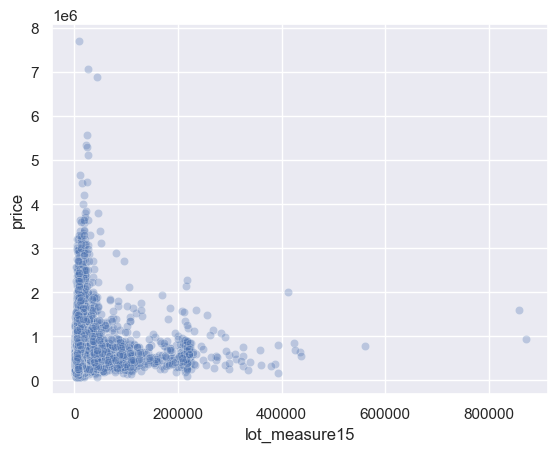

In [152]:
sns.scatterplot(x='lot_measure15', y="price", data=df, alpha=0.3);

In [153]:
df['furnished'].isna().sum()

29

In [154]:
df['furnished'].nunique()

2

In [155]:
df['furnished'].value_counts()

furnished
0.0    17326
1.0     4241
Name: count, dtype: int64

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\2418461504.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  chart=sns.boxplot(x="furnished", y="price", data=df, palette="viridis")
C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\2418461504.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), horizontalalignment='right', fontsize=18)


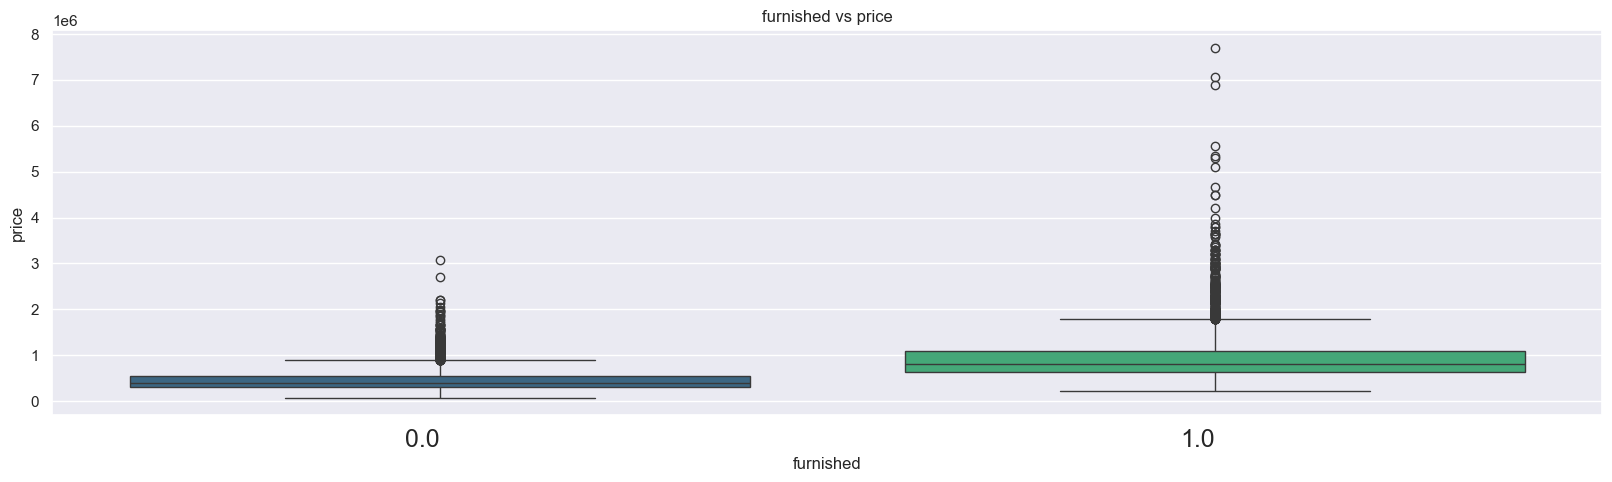

In [156]:
plt.figure(figsize=(20,5))

chart=sns.boxplot(x="furnished", y="price", data=df, palette="viridis")
chart.set_xticklabels(chart.get_xticklabels(), horizontalalignment='right', fontsize=18)
plt.title('furnished vs price')
chart;

In [157]:
df['total_area'].isna().sum()

29

In [158]:
df['total_area'].nunique()

11140

In [159]:
df['total_area'].value_counts()

total_area
$        39
5940     19
9820     19
8750     19
6770     19
         ..
5355      1
12215     1
46580     1
15588     1
38122     1
Name: count, Length: 11140, dtype: int64

In [160]:
df['total_area'] = pd.to_numeric(df['total_area'], errors='coerce')

In [161]:
df['total_area'].describe()

count    2.152800e+04
mean     1.719320e+04
std      4.164197e+04
min      1.423000e+03
25%      7.031500e+03
50%      9.576000e+03
75%      1.300000e+04
max      1.652659e+06
Name: total_area, dtype: float64

In [162]:
df['total_area'].value_counts()

total_area
9820.0     19
6770.0     19
5940.0     19
8750.0     19
7330.0     19
           ..
5355.0      1
12215.0     1
46580.0     1
15588.0     1
38122.0     1
Name: count, Length: 11139, dtype: int64

In [163]:
df['total_area'].isna().sum()

68

In [164]:
df['total_area'].min()

1423.0

In [165]:
df['total_area'].max()

1652659.0

<Axes: xlabel='total_area'>

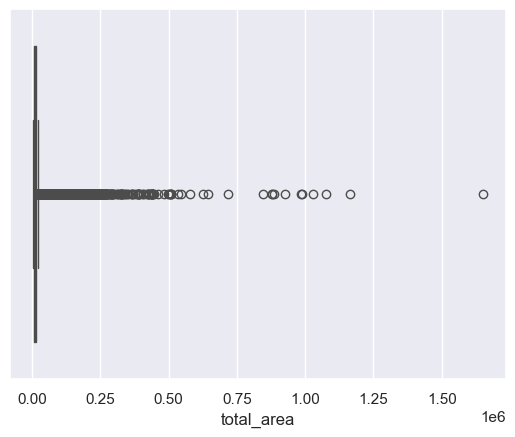

In [166]:
sns.boxplot(x=df['total_area'])

C:\Users\cylik\AppData\Local\Temp\ipykernel_16064\4244064299.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='total_area', data=df, palette='viridis')


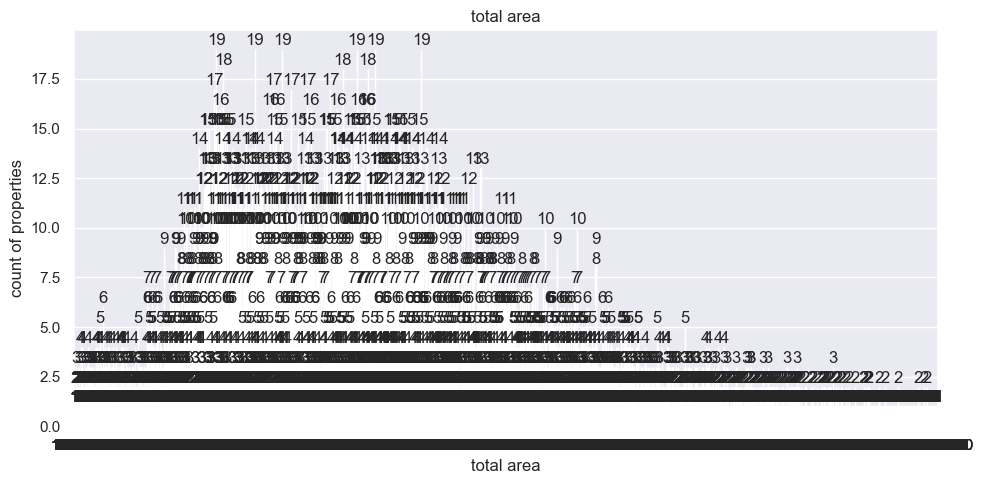

In [167]:
# Create the countplot
plt.figure(figsize=(10, 5))
ax = sns.countplot(x='total_area', data=df, palette='viridis')

# Add count labels on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 0.2, int(height), ha="center")

# Add titles and axis labels
plt.title("total area")
plt.xlabel("total area")
plt.ylabel("count of properties")

# Display the plot
plt.tight_layout()
plt.show()

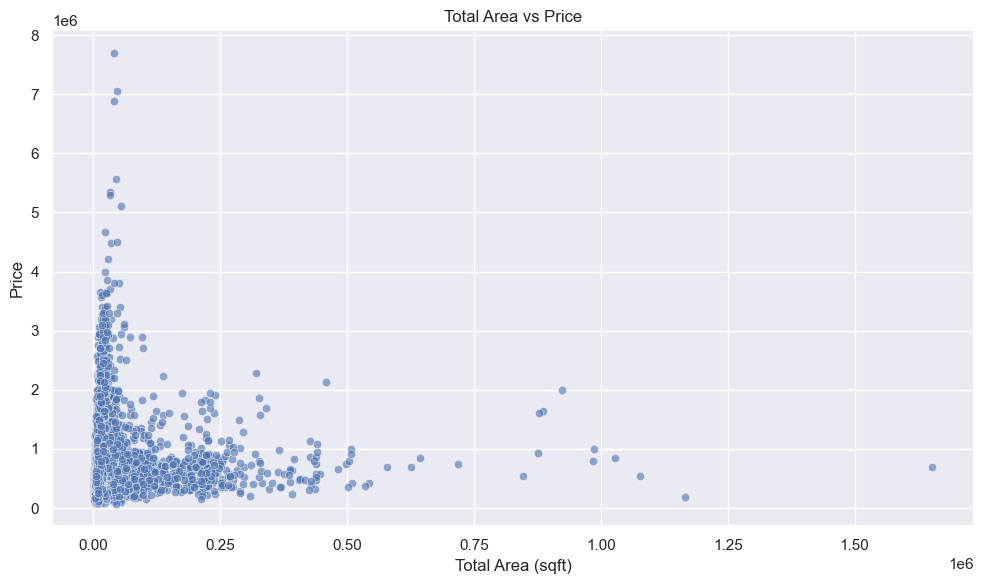

In [168]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='total_area', y='price', data=df, alpha=0.6)
plt.title('Total Area vs Price')
plt.xlabel('Total Area (sqft)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [169]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21596 entries, 0 to 21612
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   price                  21596 non-null  int64   
 1   room_bed               21505 non-null  float64 
 2   room_bath              21505 non-null  float64 
 3   living_measure         21596 non-null  float64 
 4   lot_measure            21554 non-null  float64 
 5   ceil                   21524 non-null  float64 
 6   coast                  21565 non-null  float64 
 7   sight                  21539 non-null  float64 
 8   condition              21511 non-null  float64 
 9   quality                21595 non-null  float64 
 10  ceil_measure           21595 non-null  float64 
 11  basement               21595 non-null  float64 
 12  zipcode                21596 non-null  int64   
 13  lat                    21596 non-null  float64 
 14  long                   21596 non-null  floa

In [170]:
columns_to_drop = ['dist_medina', 'dist_seattle', 'dist_bellevue', 'dist_redmond', 'dist_kirkland']
df = df.drop(columns=columns_to_drop)

In [171]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21596 entries, 0 to 21612
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   price                  21596 non-null  int64   
 1   room_bed               21505 non-null  float64 
 2   room_bath              21505 non-null  float64 
 3   living_measure         21596 non-null  float64 
 4   lot_measure            21554 non-null  float64 
 5   ceil                   21524 non-null  float64 
 6   coast                  21565 non-null  float64 
 7   sight                  21539 non-null  float64 
 8   condition              21511 non-null  float64 
 9   quality                21595 non-null  float64 
 10  ceil_measure           21595 non-null  float64 
 11  basement               21595 non-null  float64 
 12  zipcode                21596 non-null  int64   
 13  lat                    21596 non-null  float64 
 14  long                   21596 non-null  floa

In [172]:
df['basement'].isna().sum()

1

In [173]:
df['basement'].value_counts()

basement
0.0       13113
600.0       221
700.0       218
500.0       214
800.0       205
          ...  
4130.0        1
2050.0        1
784.0         1
518.0         1
2180.0        1
Name: count, Length: 306, dtype: int64

In [174]:
df.drop(['basement'],axis='columns', inplace=True) ## drop b asement column

In [175]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21596 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   price                  21596 non-null  int64   
 1   room_bed               21505 non-null  float64 
 2   room_bath              21505 non-null  float64 
 3   living_measure         21596 non-null  float64 
 4   lot_measure            21554 non-null  float64 
 5   ceil                   21524 non-null  float64 
 6   coast                  21565 non-null  float64 
 7   sight                  21539 non-null  float64 
 8   condition              21511 non-null  float64 
 9   quality                21595 non-null  float64 
 10  ceil_measure           21595 non-null  float64 
 11  zipcode                21596 non-null  int64   
 12  lat                    21596 non-null  float64 
 13  long                   21596 non-null  float64 
 14  living_measure15       21430 non-null  floa

In [176]:
df['basement_size'].isna().sum()

13114

In [177]:
df.drop(['basement_size'],axis='columns', inplace=True) ## drop basement_size column

In [178]:
df.isna().sum()

price                      0
room_bed                  91
room_bath                 91
living_measure             0
lot_measure               42
ceil                      72
coast                     31
sight                     57
condition                 85
quality                    1
ceil_measure               1
zipcode                    0
lat                        0
long                       0
living_measure15         166
lot_measure15             29
furnished                 29
total_area                68
days_until_2025_06_01      0
house_age_2025            15
dist_average               0
dtype: int64

In [179]:
df.shape

(21596, 21)

In [180]:
df = df.dropna(subset=['room_bed', 'room_bath'])

In [181]:
df.shape

(21505, 21)

In [182]:
df.isna().sum()

price                     0
room_bed                  0
room_bath                 0
living_measure            0
lot_measure              42
ceil                     72
coast                    31
sight                    46
condition                46
quality                   1
ceil_measure              1
zipcode                   0
lat                       0
long                      0
living_measure15         75
lot_measure15            29
furnished                29
total_area               68
days_until_2025_06_01     0
house_age_2025            1
dist_average              0
dtype: int64

In [183]:
df = df.drop(columns=['lat', 'long','zipcode'])

In [184]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21505 entries, 0 to 21612
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  21505 non-null  int64  
 1   room_bed               21505 non-null  float64
 2   room_bath              21505 non-null  float64
 3   living_measure         21505 non-null  float64
 4   lot_measure            21463 non-null  float64
 5   ceil                   21433 non-null  float64
 6   coast                  21474 non-null  float64
 7   sight                  21459 non-null  float64
 8   condition              21459 non-null  float64
 9   quality                21504 non-null  float64
 10  ceil_measure           21504 non-null  float64
 11  living_measure15       21430 non-null  float64
 12  lot_measure15          21476 non-null  float64
 13  furnished              21476 non-null  float64
 14  total_area             21437 non-null  float64
 15  days_un

In [185]:
df1=df.copy()

In [186]:
df2=df.copy()

In [187]:
def fill_na_with_mean(df1, columns):
    """
    Fills NaN values in specified columns with the column mean.
    
    Parameters:
        df (pd.DataFrame): The dataframe to process.
        columns (list): List of column names to impute with mean.
        
    Returns:
        pd.DataFrame: Dataframe with NaNs replaced by mean in specified columns.
    """
    df_filled = df1.copy()
    for col in columns:
        if col in df_filled.columns:
            mean_val = df_filled[col].mean()
            df_filled[col] = df_filled[col].fillna(mean_val)
    return df_filled

In [188]:
cols_to_impute = [ 'lot_measure','ceil_measure','living_measure15','lot_measure15','total_area','house_age_2025']
df1 = fill_na_with_mean(df1, cols_to_impute)

In [189]:
df1.isna().sum()

price                     0
room_bed                  0
room_bath                 0
living_measure            0
lot_measure               0
ceil                     72
coast                    31
sight                    46
condition                46
quality                   1
ceil_measure              0
living_measure15          0
lot_measure15             0
furnished                29
total_area                0
days_until_2025_06_01     0
house_age_2025            0
dist_average              0
dtype: int64

In [190]:
def fill_na_with_mode(df1, columns):
    """
    Fills NaN values in specified columns with the mode (most frequent value).
    
    Parameters:
        df (pd.DataFrame): The DataFrame to process.
        columns (list): List of column names to impute with mode.
        
    Returns:
        pd.DataFrame: DataFrame with NaNs replaced by mode in specified columns.
    """
    df_filled = df1.copy()
    for col in columns:
        if col in df_filled.columns:
            mode_val = df_filled[col].mode()
            if not mode_val.empty:
                df_filled[col] = df_filled[col].fillna(mode_val[0])
    return df_filled

In [191]:
cols_to_impute = ['ceil','coast','sight','condition','quality','furnished']
df1 = fill_na_with_mode(df1, cols_to_impute)

In [192]:
df1.isna().sum()

price                    0
room_bed                 0
room_bath                0
living_measure           0
lot_measure              0
ceil                     0
coast                    0
sight                    0
condition                0
quality                  0
ceil_measure             0
living_measure15         0
lot_measure15            0
furnished                0
total_area               0
days_until_2025_06_01    0
house_age_2025           0
dist_average             0
dtype: int64

In [193]:
df1.head()

,price,room_bed,room_bath,living_measure,lot_measure,ceil,coast,sight,condition,quality,ceil_measure,living_measure15,lot_measure15,furnished,total_area,days_until_2025_06_01,house_age_2025,dist_average
0,600000,4.0,1.75,3050.0,9440.0,1.0,0.0,0.0,3.0,8.0,1800.0,2020.0,8660.0,0.0,12490.0,3688,59.0,10.759063
1,190000,2.0,1.00,670.0,3101.0,1.0,0.0,0.0,4.0,6.0,670.0,1660.0,4100.0,0.0,3771.0,3729,77.0,11.180239
2,735000,4.0,2.75,3040.0,2415.0,2.0,1.0,4.0,3.0,8.0,3040.0,2620.0,2433.0,0.0,5455.0,3938,59.0,14.418058
3,257000,3.0,2.50,1740.0,3721.0,2.0,0.0,0.0,3.0,8.0,1740.0,2030.0,3794.0,0.0,5461.0,3887,16.0,33.989546
4,450000,2.0,1.00,1120.0,4590.0,1.0,0.0,0.0,3.0,7.0,1120.0,1120.0,5100.0,0.0,5710.0,3756,101.0,10.409826


In [194]:
df1['coast'].unique()

array([0., 1.])

In [195]:
df1['furnished'].unique()

array([0., 1.])

In [196]:
def treat_outliers_iqr(df1, columns, factor=1.5):
    """
    Treats outliers by clipping values outside the IQR range.
    
    Parameters:
        df (pd.DataFrame): The DataFrame to process.
        columns (list): List of numerical columns to apply outlier treatment.
        factor (float): Multiplier for IQR to define bounds (default is 1.5).
        
    Returns:
        pd.DataFrame: A copy of the DataFrame with outliers clipped.
    """
    df_out = df1.copy()
    for col in columns:
        if col in df_out.columns:
            Q1 = df_out[col].quantile(0.25)
            Q3 = df_out[col].quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - factor * IQR
            upper = Q3 + factor * IQR
            df_out[col] = df_out[col].clip(lower, upper)
    return df_out

In [197]:
cols_to_fix = ['room_bed','room_bath','living_measure','ceil','sight','condition','ceil_measure','quality','lot_measure','living_measure15','lot_measure15', 'total_area','price',
               'days_until_2025_06_01','days_until_2025_06_01']
df1 = treat_outliers_iqr(df1, cols_to_fix)

In [198]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21505 entries, 0 to 21612
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  21505 non-null  float64
 1   room_bed               21505 non-null  float64
 2   room_bath              21505 non-null  float64
 3   living_measure         21505 non-null  float64
 4   lot_measure            21505 non-null  float64
 5   ceil                   21505 non-null  float64
 6   coast                  21505 non-null  float64
 7   sight                  21505 non-null  float64
 8   condition              21505 non-null  float64
 9   quality                21505 non-null  float64
 10  ceil_measure           21505 non-null  float64
 11  living_measure15       21505 non-null  float64
 12  lot_measure15          21505 non-null  float64
 13  furnished              21505 non-null  float64
 14  total_area             21505 non-null  float64
 15  days_un

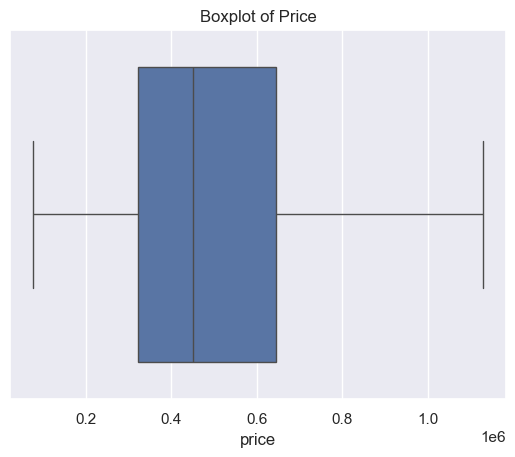

In [199]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df1['price'])
plt.title("Boxplot of Price")
plt.show()

In [200]:
df1.isna().sum()

price                    0
room_bed                 0
room_bath                0
living_measure           0
lot_measure              0
ceil                     0
coast                    0
sight                    0
condition                0
quality                  0
ceil_measure             0
living_measure15         0
lot_measure15            0
furnished                0
total_area               0
days_until_2025_06_01    0
house_age_2025           0
dist_average             0
dtype: int64

In [201]:
df1.head(10)

,price,room_bed,room_bath,living_measure,lot_measure,ceil,coast,sight,condition,quality,ceil_measure,living_measure15,lot_measure15,furnished,total_area,days_until_2025_06_01,house_age_2025,dist_average
0,600000.0,4.0,1.75,3050.0,9440.0,1.0,0.0,0.0,3.0,8.0,1800.0,2020.0,8660.0,0.0,12490.0,3688,59.0,10.759063
1,190000.0,2.0,1.00,670.0,3101.0,1.0,0.0,0.0,4.0,6.0,670.0,1660.0,4100.0,0.0,3771.0,3729,77.0,11.180239
2,735000.0,4.0,2.75,3040.0,2415.0,2.0,1.0,0.0,3.0,8.0,3040.0,2620.0,2433.0,0.0,5455.0,3938,59.0,14.418058
3,257000.0,3.0,2.50,1740.0,3721.0,2.0,0.0,0.0,3.0,8.0,1740.0,2030.0,3794.0,0.0,5461.0,3887,16.0,33.989546
4,450000.0,2.0,1.00,1120.0,4590.0,1.0,0.0,0.0,3.0,7.0,1120.0,1120.0,5100.0,0.0,5710.0,3756,101.0,10.409826
5,245000.0,3.0,2.50,1610.0,7223.0,2.0,0.0,0.0,3.0,7.0,1610.0,1610.0,7162.0,0.0,8833.0,3980,31.0,31.109779
6,466000.0,2.0,1.50,1140.0,1058.0,3.0,0.0,0.0,3.0,7.0,1140.0,1170.0,1116.0,0.0,2198.0,3974,20.0,10.367450
7,1130959.5,4.0,3.50,4230.0,9700.0,2.0,0.0,0.0,3.0,9.5,3360.0,2800.0,12343.0,1.0,14380.0,4001,20.0,10.096904
8,449950.0,4.0,2.50,3100.0,10000.0,2.0,0.0,0.0,3.0,9.0,3100.0,1850.0,9438.0,1.0,13100.0,3968,47.0,30.328458
9,299950.0,2.0,1.75,1460.0,10506.0,1.0,0.0,0.0,3.0,7.0,1460.0,1460.0,8153.0,0.0,11966.0,3869,42.0,26.693008


In [202]:
df1['coast'] = df1['coast'].astype(int)

In [203]:
df1['furnished'] = df1['furnished'].astype(int)

In [204]:
df1['ceil'] = df1['ceil'].astype(int)

In [205]:
df1['condition'] = df1['condition'].astype(int)
df1['quality'] = df1['quality'].astype(int)

In [206]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21505 entries, 0 to 21612
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  21505 non-null  float64
 1   room_bed               21505 non-null  float64
 2   room_bath              21505 non-null  float64
 3   living_measure         21505 non-null  float64
 4   lot_measure            21505 non-null  float64
 5   ceil                   21505 non-null  int32  
 6   coast                  21505 non-null  int32  
 7   sight                  21505 non-null  float64
 8   condition              21505 non-null  int32  
 9   quality                21505 non-null  int32  
 10  ceil_measure           21505 non-null  float64
 11  living_measure15       21505 non-null  float64
 12  lot_measure15          21505 non-null  float64
 13  furnished              21505 non-null  int32  
 14  total_area             21505 non-null  float64
 15  days_un

In [207]:
df1.head(10)

,price,room_bed,room_bath,living_measure,lot_measure,ceil,coast,sight,condition,quality,ceil_measure,living_measure15,lot_measure15,furnished,total_area,days_until_2025_06_01,house_age_2025,dist_average
0,600000.0,4.0,1.75,3050.0,9440.0,1,0,0.0,3,8,1800.0,2020.0,8660.0,0,12490.0,3688,59.0,10.759063
1,190000.0,2.0,1.00,670.0,3101.0,1,0,0.0,4,6,670.0,1660.0,4100.0,0,3771.0,3729,77.0,11.180239
2,735000.0,4.0,2.75,3040.0,2415.0,2,1,0.0,3,8,3040.0,2620.0,2433.0,0,5455.0,3938,59.0,14.418058
3,257000.0,3.0,2.50,1740.0,3721.0,2,0,0.0,3,8,1740.0,2030.0,3794.0,0,5461.0,3887,16.0,33.989546
4,450000.0,2.0,1.00,1120.0,4590.0,1,0,0.0,3,7,1120.0,1120.0,5100.0,0,5710.0,3756,101.0,10.409826
5,245000.0,3.0,2.50,1610.0,7223.0,2,0,0.0,3,7,1610.0,1610.0,7162.0,0,8833.0,3980,31.0,31.109779
6,466000.0,2.0,1.50,1140.0,1058.0,3,0,0.0,3,7,1140.0,1170.0,1116.0,0,2198.0,3974,20.0,10.367450
7,1130959.5,4.0,3.50,4230.0,9700.0,2,0,0.0,3,9,3360.0,2800.0,12343.0,1,14380.0,4001,20.0,10.096904
8,449950.0,4.0,2.50,3100.0,10000.0,2,0,0.0,3,9,3100.0,1850.0,9438.0,1,13100.0,3968,47.0,30.328458
9,299950.0,2.0,1.75,1460.0,10506.0,1,0,0.0,3,7,1460.0,1460.0,8153.0,0,11966.0,3869,42.0,26.693008


In [208]:
df['room_bed'].unique()

array([ 4.,  2.,  3.,  1.,  5.,  6.,  7., 10.,  8.,  0.,  9., 33., 11.])

In [209]:
df1['room_bed'].unique()

array([4. , 2. , 3. , 1.5, 5. , 5.5])

In [210]:
df['room_bath'].unique()

array([1.75, 1.  , 2.75, 2.5 , 1.5 , 3.5 , 2.  , 2.25, 3.  , 4.  , 3.25,
       3.75, 5.  , 0.75, 5.5 , 4.25, 4.5 , 4.75, 8.  , 6.75, 5.25, 6.  ,
       0.  , 1.25, 5.75, 7.5 , 6.5 , 0.5 , 7.75, 6.25])

In [211]:
df1['room_bath'].unique()

array([1.75 , 1.   , 2.75 , 2.5  , 1.5  , 3.5  , 2.   , 2.25 , 3.   ,
       3.625, 3.25 , 0.75 , 0.625, 1.25 ])